# 🐄🥛🚚 Dairy Supply-Chain Digital Twin — توأم رقمي ديناميكي لسلسلة إمداد الألبان

**من الحلب في المزرعة ← خزانات التبريد ← صهاريج الجمع ← الاستلام والصومعة ← التصنيع ← مخزن التبريد ← الطلب**

| المحور | المحتوى |
|---|---|
| 1. دمج البيانات ومعايرتها | اكتشاف تلقائي لمجموعات Kaggle الخمس، مطابقة مرنة للأعمدة، ومعايرة المعاملات مع سجل مصدر كل معامل (Provenance) |
| 2. محرك التوأم الرقمي | محاكاة هجينة: أحداث متقطعة (SimPy: صهاريج، طوابير استلام، أعطال، توريد أعلاف) + فيزياء زمنية مستمرة (حرارة، تبريد، نمو ميكروبي، حلب، طلب) |
| 3. سيناريوهات «ماذا لو؟» | S1 تشغيل قياسي · S2 اضطراب التبريد والإجهاد الحراري · S3 اضطراب النقل والتأخير · (إضافي) S4 مركّب · S5 مركّب مع إجراءات تخفيف |
| 4. المؤشرات والاستنتاجات | مسارات زمنية، تكرارات Monte-Carlo بفواصل ثقة 95%، تحليل حساسية، جدول مقارنة، واستنتاجات هندسية تُولَّد آلياً من النتائج |

### طريقة التشغيل على Kaggle
1. من **Add Input** أضف المجموعات التالية (أي مجموعة غير مضافة تُستبدل تلقائياً بقيم مرجعية من الأدبيات العلمية، ويُذكر ذلك صراحة في جدول المصادر):
   - `hienvuvg/mmcows` — MmCows (حساسات المزرعة، THI، حرارة الجسم، الإنتاج)
   - `amithadityacp/cow-mastitisfrom-milk` — Cow Mastitis IoT
   - `u201411546/data-sets-cold-chain-milk` — Cold Chain Milk
   - `likithagedipudi/perishable-goods-management` — Perishable Goods Management
   - `shrutithakur13/dairy-sales-and-inventory-data` — Country Delight Dairy Sales & Inventory
2. **Run All**. يكفي CPU (المحرك لا يحتاج GPU). زمن التشغيل الكامل ≈ 2–5 دقائق.
3. كل المخرجات (جداول CSV + رسوم PNG) تُحفظ في `/kaggle/working/dt_outputs`.

> **قابلية إعادة الإنتاج:** بذرة عشوائية ثابتة + أرقام عشوائية مشتركة (Common Random Numbers) بين السيناريوهات، بحيث يُعزى الفرق بين السيناريوهات إلى الاضطراب نفسه لا إلى الضجيج العشوائي.

## 0. الإعدادات العامة (Configuration)
كل ما يحتاج المستخدم لتعديله موجود في هذه الخلية: أفق المحاكاة، عدد التكرارات، ومسارات يدوية للبيانات عند الحاجة.

In [1]:
import os, re, sys, math, json, time, warnings, random
from dataclasses import dataclass, field, replace, asdict
from collections import deque, defaultdict

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

try:
    import simpy
except ImportError:  # Kaggle images usually need this once
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "simpy"])
    import simpy

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

# ---------------- user-editable settings ----------------
SEED         = 2026        # master seed (reproducibility)
SIM_DAYS     = 60          # simulated horizon (days)
WARMUP_DAYS  = 5           # excluded from KPIs (initial-condition bias)
DT           = 0.5         # continuous-physics time step (hours)
N_REPS       = 20          # Monte-Carlo replications per scenario
SWEEP_REPS   = 10          # replications per sensitivity point
MAX_ROWS     = 300_000     # row cap per file (MmCows is very large)
INPUT_ROOTS  = ["/kaggle/input", "./data", "../input"]
OUT_DIR      = "/kaggle/working/dt_outputs" if os.path.isdir("/kaggle/working") else "./dt_outputs"

# Keywords used to recognise each dataset from its path (case/punctuation-insensitive)
DATASET_KEYS = {
    "mmcows":     ["mmcows", "mm cows"],
    "mastitis":   ["mastitis"],
    "coldchain":  ["cold chain milk", "data sets cold chain", "coldchainmilk", "cold chain"],
    "perishable": ["perishable"],
    "sales":      ["dairy sales", "diary sales", "country delight", "sales and inventory"],
}
# Optional manual override, e.g. {"sales": "/kaggle/input/xyz/file.csv"}
MANUAL_PATHS = {}
# --------------------------------------------------------

os.makedirs(OUT_DIR, exist_ok=True)
np.random.seed(SEED); random.seed(SEED)
print(f"Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | simpy {simpy.__version__}")
print("Outputs ->", os.path.abspath(OUT_DIR))

Python 3.13.15 | numpy 2.1.3 | pandas 2.3.3 | simpy 4.1.2
Outputs -> /kaggle/working/dt_outputs


## 1. طبقة استيعاب البيانات (Data Ingestion Layer)
- **اكتشاف تلقائي** لكل الملفات تحت `/kaggle/input` وتصنيفها حسب اسم المسار، ثم حسب **محتوى الأعمدة** عند الحاجة.
- **مطابقة مرنة للأعمدة** (`find_col`): تتجاهل حالة الأحرف والرموز، فيعمل الكود حتى لو تغيّرت أسماء الأعمدة قليلاً بين إصدارات المجموعة.
- كل معامل يُعايَر يُسجَّل في **سجل المصادر (Provenance)**: هل جاء من البيانات أم من قيمة مرجعية علمية؟

In [2]:
PROVENANCE = []

def log_param(group, name, value, source, note=""):
    PROVENANCE.append({"group": group, "parameter": name,
                       "value": (round(value, 4) if isinstance(value, (int, float, np.floating)) else value),
                       "source": source, "note": note})

def norm(s):
    return re.sub(r"[^a-z0-9]+", " ", str(s).lower()).strip()

def discover_files(exts=(".csv", ".xlsx", ".xls", ".parquet", ".json")):
    found = []
    for root in INPUT_ROOTS:
        if os.path.isdir(root):
            for dp, _, fn in os.walk(root):
                for f in fn:
                    if f.lower().endswith(exts):
                        found.append(os.path.join(dp, f))
    return sorted(set(found))

def read_table(path, nrows=MAX_ROWS, usecols=None):
    p = path.lower()
    try:
        if p.endswith(".csv"):
            for enc in ("utf-8", "latin-1"):
                try:
                    return pd.read_csv(path, nrows=nrows, low_memory=False, encoding=enc, usecols=usecols)
                except UnicodeDecodeError:
                    continue
        elif p.endswith((".xlsx", ".xls")):
            return pd.read_excel(path, nrows=nrows)
        elif p.endswith(".parquet"):
            return pd.read_parquet(path).head(nrows)
        elif p.endswith(".json"):
            return pd.read_json(path).head(nrows)
    except Exception as e:
        print(f"   [skip] {os.path.basename(path)}: {type(e).__name__}: {str(e)[:80]}")
    return None

def header_of(path):
    df = read_table(path, nrows=5)
    return [] if df is None else [norm(c) for c in df.columns]

# content signatures for files whose path is not informative
CONTENT_SIGNATURES = {
    "sales":      [["quantity sold"], ["reorder quantity"]],
    "perishable": [["shelf life days", "category"]],
    "mastitis":   [["somatic"], ["mastitis"], ["conductivity", "class"]],
    "coldchain":  [["temperature", "milk"], ["temp", "cold"]],
    "mmcows":     [["thi"], ["cbt"]],
}

def classify_files(files):
    groups = {k: [] for k in DATASET_KEYS}
    unmatched = []
    for f in files:
        nf = norm(f)
        hit = [k for k, keys in DATASET_KEYS.items() if any(norm(x) in nf for x in keys)]
        if hit:
            groups[hit[0]].append(f)
        else:
            unmatched.append(f)
    for f in unmatched[:200]:                      # content sniffing (header only)
        cols = " | ".join(header_of(f))
        for k, sigs in CONTENT_SIGNATURES.items():
            if any(all(tok in cols for tok in sig) for sig in sigs):
                groups[k].append(f); break
    for k, p in MANUAL_PATHS.items():
        groups[k] = [p] if isinstance(p, str) else list(p)
    return groups

def find_col(df, candidates, exclude=()):
    """Return the first column whose normalised name contains all tokens of a candidate."""
    if df is None:
        return None
    cols = {c: norm(c) for c in df.columns}
    for cand in candidates:
        toks = norm(cand).split()
        for c, nc in cols.items():
            if all(t in nc for t in toks) and not any(norm(e) in nc for e in exclude):
                return c
    return None

def to_num(s):
    return pd.to_numeric(s, errors="coerce")

def parse_time(s):
    """Robust datetime parser: unix seconds/ms or strings (day-first fallback)."""
    if pd.api.types.is_numeric_dtype(s):
        v = s.dropna()
        if len(v) == 0:
            return pd.to_datetime(s, errors="coerce")
        unit = "ms" if v.median() > 1e11 else "s"
        return pd.to_datetime(s, unit=unit, errors="coerce")
    sample = s.dropna().astype(str).str.strip()
    iso = len(sample) > 0 and sample.str.match(r"^\d{4}[-/]").mean() > 0.8
    t = pd.to_datetime(s, errors="coerce", dayfirst=not iso)
    if t.isna().mean() > 0.5:
        t = pd.to_datetime(s, errors="coerce", format="mixed", dayfirst=not iso)
    return t

FILES = discover_files()
GROUPS = classify_files(FILES)
print(f"Discovered {len(FILES)} tabular files under {INPUT_ROOTS}\n")
audit = []
for k, fl in GROUPS.items():
    audit.append({"dataset": k, "files_found": len(fl),
                  "examples": "; ".join(os.path.basename(x) for x in fl[:3]) or "— not attached → literature defaults"})
display_df = pd.DataFrame(audit)
print(display_df.to_string(index=False))

Discovered 2774 tabular files under ['/kaggle/input', './data', '../input']

   dataset  files_found                                                                                                                        examples
    mmcows         2400                                                                                        C01_0725.csv; C02_0725.csv; C03_0725.csv
  mastitis            2                                                                    cow_milk_mastitis_dataset.csv; cow_milk_mastitis_dataset.csv
 coldchain          368                                                                                Datos (1).xlsx; Datos (10).xlsx; Datos (11).xlsx
perishable            0                                                                                            — not attached → literature defaults
     sales            4 Country Delight Diary Sales and Inventory Dataset.csv; Country Delight Diary Sales and Inventory Dataset.csv; dairy_dataset.csv


## 2. المعايرة (Calibration) — من البيانات إلى معاملات التوأم الرقمي

### 2.1 طبقة المزرعة: MmCows + Cow Mastitis IoT
**النماذج المستخدمة:**
- مؤشر الحرارة والرطوبة (NRC, 1971): $THI = (1.8T+32) - (0.55-0.0055\,RH)(1.8T-26)$
- فقد الإنتاج بالإجهاد الحراري (Bouraoui et al., 2002): $Y = Y_0 - b\cdot\max(THI_{24h}-THI_{thr},0)$ ، القيمة المرجعية $b=0.41$ كغ/بقرة/يوم لكل وحدة THI فوق 69.
- من بيانات الالتهاب (Mastitis): نختار آلياً أفضل حساس IoT (حرارة الحليب، الموصلية، الخلايا الجسدية…) وأفضل عتبة له بمعيار **Youden J**، فتخرج **حساسية ونوعية** نظام الإنذار. يستعملها التوأم لتحديد الحليب المُستبعد (المُحوَّل) من الأبقار المنبَّه عليها.

In [3]:
FARM = dict(
    yield_l=25.0,          # L/cow/day
    thi_thr=69.0,          # THI threshold
    yield_loss_thi=0.41,   # L/cow/day per THI unit above threshold
    amb_mean=22.0, amb_amp=6.0, rh_mean=50.0,
    mast_prev=0.04,        # clinical prevalence (fraction of cows)
    mast_heat_slope=0.004, # +prevalence per THI unit above threshold
    sens=0.85, spec=0.95,  # IoT mastitis alarm performance
    mast_yield_ratio=0.85, # yield of mastitic cow / healthy
    cbt_stress_frac=np.nan,
)
CAL_DATA = {}  # stores arrays for calibration plots

def youden_best(x, y):
    x, y = np.asarray(x, float), np.asarray(y, int)
    m = ~np.isnan(x); x, y = x[m], y[m]
    if len(np.unique(y)) < 2 or len(x) < 20:
        return None
    best = None
    for direction in (1, -1):
        for thr in np.unique(np.quantile(x, np.linspace(0.02, 0.98, 97))):
            pred = (direction * x >= direction * thr).astype(int)
            tp = ((pred == 1) & (y == 1)).sum(); fn = ((pred == 0) & (y == 1)).sum()
            tn = ((pred == 0) & (y == 0)).sum(); fp = ((pred == 1) & (y == 0)).sum()
            se = tp / max(tp + fn, 1); sp = tn / max(tn + fp, 1)
            if best is None or se + sp - 1 > best[0]:
                best = (se + sp - 1, thr, direction, se, sp)
    return best

def to_binary_label(s):
    if pd.api.types.is_numeric_dtype(s):
        v = to_num(s)
        return (v > v.min()).astype(int) if v.nunique() == 2 else (v > 0).astype(int)
    st = s.astype(str).str.lower()
    pos = st.str.contains("mastitis|yes|positive|sick|infect|abnormal|^1$")
    neg = st.str.contains("healthy|no mastitis|negative|normal|^0$")
    return np.where(neg, 0, np.where(pos, 1, 0)).astype(int)

def calibrate_mastitis(files):
    for f in files:
        df = read_table(f)
        if df is None or len(df) < 20:
            continue
        lab = find_col(df, ["mastitis", "class", "target", "status", "label", "diagnosis"],
                       exclude=["previous", "history", "id"])
        if lab is None:
            continue
        y = to_binary_label(df[lab])
        if y.mean() in (0, 1):
            continue
        name = os.path.basename(f)
        log_param("farm", "mastitis_label_rate_in_dataset", float(y.mean()), f"DATA:{name}",
                  "class balance of the dataset (not used as herd prevalence: clinical datasets are enriched)")
        feats = [c for c in df.columns if c != lab and pd.api.types.is_numeric_dtype(df[c])
                 and not re.search(r"id|day$|^day|age|breed|calv", norm(c))]
        res = []
        for c in feats:
            b = youden_best(to_num(df[c]), y)
            if b: res.append((b[0], c, b))
        if not res:
            continue
        res.sort(reverse=True)
        J, col, (J, thr, d, se, sp) = res[0]
        FARM["sens"], FARM["spec"] = float(se), float(sp)
        log_param("farm", "iot_alarm_feature", col, f"DATA:{name}", f"best single sensor by Youden J={J:.2f}")
        log_param("farm", "iot_alarm_threshold", float(thr), f"DATA:{name}", f"alarm if value {'>=' if d==1 else '<='} threshold")
        log_param("farm", "sens", FARM["sens"], f"DATA:{name}", "sensitivity of IoT alarm")
        log_param("farm", "spec", FARM["spec"], f"DATA:{name}", "specificity of IoT alarm")
        CAL_DATA["mastitis"] = dict(x=to_num(df[col]).values, y=np.asarray(y), col=col, thr=thr,
                                    ranking=[(c, round(j, 3)) for j, c, _ in res[:6]])
        ycol = find_col(df, ["milk yield", "yield", "milk production", "milk volume"])
        if ycol is not None:
            yy = to_num(df[ycol])
            h, s_ = yy[np.asarray(y) == 0].mean(), yy[np.asarray(y) == 1].mean()
            if h > 0 and 0.3 < s_ / h <= 1.05:
                FARM["mast_yield_ratio"] = float(s_ / h)
                log_param("farm", "mast_yield_ratio", FARM["mast_yield_ratio"], f"DATA:{name}", "yield mastitic/healthy")
            if 5 < h < 60:
                FARM["yield_l"] = float(h)
                log_param("farm", "yield_l", FARM["yield_l"], f"DATA:{name}", "mean daily yield of healthy cows")
        return True
    return False

MM_KEYWORDS = ("thi", "temp", "weather", "ambient", "cbt", "milk", "yield", "humid", "health", "environment")

def calibrate_mmcows(files):
    cand = [f for f in files if f.lower().endswith((".csv", ".xlsx", ".parquet"))
            and any(k in norm(f) for k in MM_KEYWORDS)]
    cand = sorted(cand, key=lambda f: os.path.getsize(f) if os.path.exists(f) else 0)[:60]
    amb, rh, thi, cbt, yld = [], [], [], [], []
    for f in cand:
        if os.path.getsize(f) > 400e6:
            continue
        df = read_table(f)
        if df is None or len(df) < 10:
            continue
        tcol = find_col(df, ["timestamp", "datetime", "time", "date"])
        tt = parse_time(df[tcol]) if tcol is not None else None
        def grab(col, store):
            if col is None: return
            v = to_num(df[col])
            if v.notna().sum() < 10: return
            store.append(pd.DataFrame({"t": tt if tt is not None else pd.NaT, "v": v}))
        grab(find_col(df, ["thi"], exclude=["this"]), thi)
        grab(find_col(df, ["cbt"]) or find_col(df, ["body temp"]), cbt)
        grab(find_col(df, ["humid"]) or find_col(df, ["rh"]), rh)
        grab(find_col(df, ["ambient temp"]) or find_col(df, ["air temp"]) or find_col(df, ["temperature"], exclude=["body", "cbt", "milk", "udder"]), amb)
        grab(find_col(df, ["milk yield"]) or find_col(df, ["yield"]) or find_col(df, ["milk"], exclude=["temp", "id"]), yld)
    ok = False
    def cat(lst): return pd.concat(lst, ignore_index=True).dropna(subset=["v"]) if lst else None
    A, H, TH, C, Y = map(cat, (amb, rh, thi, cbt, yld))
    if A is not None and len(A) > 50:
        a = A[(A.v > -30) & (A.v < 55)]
        if len(a) > 50:
            FARM["amb_mean"] = float(a.v.mean()); ok = True
            log_param("farm", "amb_mean", FARM["amb_mean"], "DATA:MmCows", "mean ambient temperature (°C)")
            if a.t.notna().mean() > 0.5:
                prof = a.groupby(a.t.dt.hour).v.mean()
                if len(prof) >= 12:
                    FARM["amb_amp"] = float((prof.max() - prof.min()) / 2)
                    CAL_DATA["amb_profile"] = prof
                    log_param("farm", "amb_amp", FARM["amb_amp"], "DATA:MmCows", "diurnal amplitude from hourly profile")
    if H is not None and len(H) > 50:
        h = H[(H.v > 0) & (H.v <= 100)]
        if len(h) > 50:
            FARM["rh_mean"] = float(h.v.mean()); ok = True
            log_param("farm", "rh_mean", FARM["rh_mean"], "DATA:MmCows", "mean relative humidity (%)")
    if C is not None and len(C) > 50:
        c = C[(C.v > 35) & (C.v < 43)]
        if len(c) > 50:
            FARM["cbt_stress_frac"] = float((c.v > 39.2).mean()); ok = True
            CAL_DATA["cbt"] = c.v.values
            log_param("farm", "cbt_stress_frac", FARM["cbt_stress_frac"], "DATA:MmCows", "share of CBT readings > 39.2 °C (heat-stress index)")
    if TH is not None and len(TH) > 50:
        CAL_DATA["thi"] = TH.v.values; ok = True
        log_param("farm", "thi_observed_mean", float(TH.v.mean()), "DATA:MmCows", "observed THI mean (validation of THI model)")
        if Y is not None and TH.t.notna().mean() > 0.5 and Y.t.notna().mean() > 0.5:
            dth = TH.groupby(TH.t.dt.date).v.mean()
            dy = Y[(Y.v > 1) & (Y.v < 80)].groupby(Y.t.dt.date).v.mean()
            j = pd.concat([dth.rename("thi"), dy.rename("y")], axis=1).dropna()
            if len(j) >= 10:
                x = np.maximum(j.thi.values - FARM["thi_thr"], 0)
                if x.std() > 0:
                    b, a0 = np.polyfit(x, j.y.values, 1)
                    CAL_DATA["thi_yield"] = j
                    if -1.5 < b < 0:
                        FARM["yield_loss_thi"] = float(-b)
                        log_param("farm", "yield_loss_thi", FARM["yield_loss_thi"], "DATA:MmCows", f"regression on {len(j)} days")
                    else:
                        log_param("farm", "yield_loss_thi_rejected_fit", float(-b), "DATA:MmCows", "implausible/insignificant slope → literature value kept")
                    if 5 < a0 < 60:
                        FARM["yield_l"] = float(a0)
                        log_param("farm", "yield_l", FARM["yield_l"], "DATA:MmCows", "intercept of THI-yield regression")
    return ok

for fn, key in ((calibrate_mmcows, "mmcows"), (calibrate_mastitis, "mastitis")):
    try:
        used = fn(GROUPS[key]) if GROUPS[key] else False
    except Exception as e:
        used = False; print(f"[warn] {key} calibration failed safely: {e}")
    print(f"{key:10s} -> {'calibrated from data' if used else 'literature defaults'}")

for k, v in FARM.items():
    if not any(p["parameter"] == k and p["group"] == "farm" for p in PROVENANCE):
        log_param("farm", k, v, "DEFAULT", "literature / engineering default")

mmcows     -> literature defaults
mastitis   -> calibrated from data


### 2.2 حركية التلف وسلسلة التبريد: Cold Chain Milk + Perishable Goods
نستخدم **نموذج Ratkowsky للجذر التربيعي** الذي يُعدّ معياراً في الميكروبيولوجيا التنبؤية لنمو البكتيريا المحبة للبرودة (Psychrotrophs) في الحليب:

$$ r(T) = \left(\frac{T - T_{min}}{T_{ref}-T_{min}}\right)^2 ,\qquad \text{Age}_{eq}(t)=\int_0^t r(T(\tau))\,d\tau $$

- **العمر المكافئ** $Age_{eq}$ مقيس بـ «ساعات مكافئة عند 4°م». يُرفض الحليب الخام إذا تجاوز حدّ القبول (72 ساعة مكافئة)، ويُعدم المنتج النهائي إذا استهلك أكثر من 70% من صلاحيته قبل البيع.
- **المعايرة:** من أزواج (درجة حرارة التخزين، مدة الصلاحية) في البيانات، نطبّق انحداراً خطياً على $\sqrt{1/SL}$ مقابل $T$، فيكون $T_{min}$ = نقطة تقاطع الخط مع محور الحرارة.
- من قراءات سلسلة التبريد نقدّر نقطة ضبط المخزن، وتذبذبها، واحتمال خروج الحرارة عن الحد المسموح (Excursion).

In [4]:
SPOIL = dict(
    Tmin=-6.0, Tref=4.0,
    raw_limit_h=72.0,       # raw-milk acceptance limit (equivalent h @4°C)
    fg_shelf_days=10.0,     # pasteurised milk shelf life @4°C
    min_remaining=0.30,     # retail requires ≥30% remaining life
    cs_set=4.0, cs_sd=0.5,  # cold-store setpoint & noise
    cs_exc_p_day=0.05,      # random cold-store excursion events / day
    cs_exc_delta=4.0,       # °C rise during a random excursion
    excursion_T=7.0,        # cold-store alarm threshold (°C)
    farm_alarm_T=8.0,       # bulk tank: ≤8 °C within 2 h after milking (EU Reg. 853/2004)
    benchmark_waste_pct=np.nan,
)

def fit_ratkowsky(T, SL):
    T, SL = np.asarray(T, float), np.asarray(SL, float)
    m = np.isfinite(T) & np.isfinite(SL) & (SL > 0) & (T > -5) & (T < 40)
    T, SL = T[m], SL[m]
    if len(T) < 15 or np.unique(np.round(T)).size < 3:
        return None
    df = pd.DataFrame({"T": np.round(T), "y": np.sqrt(1.0 / SL)})
    g = df.groupby("T").y.median().reset_index()
    if len(g) < 3:
        return None
    b, a = np.polyfit(g["T"], g["y"], 1)
    if b <= 0:
        return None
    return dict(Tmin=-a / b, slope=b, points=g)

def calibrate_spoilage(per_files, cc_files):
    used = False
    for f in per_files:                                 # Perishable Goods Management
        df = read_table(f)
        if df is None: continue
        name = os.path.basename(f)
        cat = find_col(df, ["category"])
        if cat is not None:
            d = df[df[cat].astype(str).str.contains("dairy", case=False, na=False)]
            if len(d) > 50: df = d
        sl = find_col(df, ["shelf life days", "shelf life", "shelf_life"])
        tc = find_col(df, ["storage temp", "storage temperature", "temperature", "temp"], exclude=["deviation", "humid"])
        if sl is not None:
            med = float(to_num(df[sl]).median())
            if 3 <= med <= 30:
                SPOIL["fg_shelf_days"] = med; used = True
                log_param("spoilage", "fg_shelf_days", med, f"DATA:{name}", "median dairy shelf life")
        if sl is not None and tc is not None:
            fit = fit_ratkowsky(to_num(df[tc]), to_num(df[sl]))
            if fit and -15 <= fit["Tmin"] <= 2:
                SPOIL["Tmin"] = float(fit["Tmin"]); CAL_DATA["ratkowsky"] = fit; used = True
                log_param("spoilage", "Tmin", SPOIL["Tmin"], f"DATA:{name}", "Ratkowsky fit (storage temp vs shelf life)")
            elif fit:
                log_param("spoilage", "Tmin_rejected_fit", float(fit["Tmin"]), f"DATA:{name}", "outside plausible range [-15,2] → default kept")
        wc = find_col(df, ["waste pct", "waste percent", "spoilage rate", "waste rate"]) or \
             find_col(df, ["waste"], exclude=["cost", "value", "flag"])
        if wc is not None:
            w = to_num(df[wc]).dropna()
            if len(w):
                val = float(w.mean() * (100 if w.max() <= 1.0 else 1))
                if 0 <= val <= 100:
                    SPOIL["benchmark_waste_pct"] = val
                    log_param("spoilage", "benchmark_waste_pct", val, f"DATA:{name}", f"mean of '{wc}' (external benchmark)")
    for f in cc_files:                                  # Cold Chain Milk
        df = read_table(f)
        if df is None: continue
        name = os.path.basename(f)
        temps = [c for c in df.columns if re.search(r"temp", norm(c)) and to_num(df[c]).notna().mean() > 0.5]
        for c in temps:
            v = to_num(df[c]).dropna()
            v = v[(v > -5) & (v < 45)]
            if len(v) < 20: continue
            cold = v[v < 15]
            if len(cold) > 20 and len(cold) / len(v) > 0.3:
                SPOIL["cs_set"] = float(np.clip(cold.median(), 1.0, 8.0))
                SPOIL["cs_sd"] = float(np.clip(cold.std(), 0.1, 3.0))
                pexc = float((v > SPOIL["excursion_T"]).mean())
                SPOIL["cs_exc_p_day"] = float(np.clip(pexc * 24 / 2.0, 0.0, 2.0))  # ~2 h per event
                CAL_DATA["coldchain_T"] = v.values; used = True
                log_param("spoilage", "cs_set", SPOIL["cs_set"], f"DATA:{name}", f"median of '{c}' cold readings")
                log_param("spoilage", "cs_sd", SPOIL["cs_sd"], f"DATA:{name}", "std of cold readings")
                log_param("spoilage", "cs_exc_p_day", SPOIL["cs_exc_p_day"], f"DATA:{name}", f"P(T>{SPOIL['excursion_T']}°C)={pexc:.3f} → events/day")
                break
        sl = find_col(df, ["shelf life", "shelf_life", "life days", "days to spoil"])
        if sl is not None and temps and "ratkowsky" not in CAL_DATA:
            fit = fit_ratkowsky(to_num(df[temps[0]]), to_num(df[sl]))
            if fit and -15 <= fit["Tmin"] <= 2:
                SPOIL["Tmin"] = float(fit["Tmin"]); CAL_DATA["ratkowsky"] = fit; used = True
                log_param("spoilage", "Tmin", SPOIL["Tmin"], f"DATA:{name}", "Ratkowsky fit")
    return used

try:
    used = calibrate_spoilage(GROUPS["perishable"], GROUPS["coldchain"])
except Exception as e:
    used = False; print("[warn] spoilage calibration failed safely:", e)
print("spoilage   ->", "calibrated from data" if used else "literature defaults")
for k, v in SPOIL.items():
    if not any(p["parameter"] == k and p["group"] == "spoilage" for p in PROVENANCE):
        log_param("spoilage", k, v, "DEFAULT", "predictive-microbiology / regulatory default")

def growth_rate(T, Tmin=None, Tref=None):
    Tmin = SPOIL["Tmin"] if Tmin is None else Tmin
    Tref = SPOIL["Tref"] if Tref is None else Tref
    x = max(T - Tmin, 0.0) / (Tref - Tmin)
    return x * x

for T in (2, 4, 7, 10, 15, 25, 35):
    print(f"  r({T:>2}°C) = {growth_rate(T):6.2f}× (raw milk life ≈ {SPOIL['raw_limit_h']/max(growth_rate(T),1e-9):7.1f} h)")

spoilage   -> calibrated from data
  r( 2°C) =   0.64× (raw milk life ≈   112.5 h)
  r( 4°C) =   1.00× (raw milk life ≈    72.0 h)
  r( 7°C) =   1.69× (raw milk life ≈    42.6 h)
  r(10°C) =   2.56× (raw milk life ≈    28.1 h)
  r(15°C) =   4.41× (raw milk life ≈    16.3 h)
  r(25°C) =   9.61× (raw milk life ≈     7.5 h)
  r(35°C) =  16.81× (raw milk life ≈     4.3 h)


### 2.3 الطلب والمخزون: Dairy Sales & Inventory (Country Delight)
- نستخرج من المبيعات **شكل الطلب**: معامل التغير اليومي (CV)، ومعاملات أيام الأسبوع، والموسمية الشهرية.
- **حجم الطلب** يُطبَّع على طاقة التوأم (حصة 85% من الحليب الصالح، والفائض يُحوَّل إلى خط الأجبان/البودرة). السبب: البيانات تجمع مزارع وولايات متعددة، أما التوأم فيمثل شبكة جمع واحدة.
- **نقطة إعادة الطلب** للمنتج النهائي (إطلاق دفعات التصنيع): $ROP = \mu_d L + z_{\alpha}\sigma_d\sqrt{L}$ ، وكمية الدفعة $Q$ مشتقة من نسبة `Reorder Quantity / Quantity Sold` في البيانات.

In [5]:
DEMAND = dict(cv=0.15, dow=np.ones(7), month=np.ones(12), share=0.85,
              service_z=1.645, lead_days=1.0, q_days=1.0,
              hour_w=None)
# retail order profile (deliveries concentrated in daytime)
_hw = np.array([0.5,0.3,0.3,0.3,0.5,1,2,3,3.5,3.5,3,2.8,2.6,2.5,2.5,2.6,2.8,3,2.6,2,1.5,1,0.8,0.6])
DEMAND["hour_w"] = _hw / _hw.sum()

def calibrate_demand(files):
    for f in files:
        df = read_table(f)
        if df is None: continue
        name = os.path.basename(f)
        dc = find_col(df, ["date"], exclude=["production", "expir", "manufact"])
        qc = find_col(df, ["quantity sold", "qty sold", "units sold", "sold"])
        if dc is None or qc is None: continue
        pc = find_col(df, ["product name", "product"])
        d = df
        if pc is not None:
            milk = df[df[pc].astype(str).str.fullmatch(r"(?i)\s*milk\s*") | df[pc].astype(str).str.contains("(?i)^milk")]
            if len(milk) > 200:
                d = milk
                log_param("demand", "product_filter", "Milk", f"DATA:{name}", f"{len(milk)} rows")
        t = parse_time(d[dc]); q = to_num(d[qc])
        s = pd.DataFrame({"t": t, "q": q}).dropna()
        s = s[s.q >= 0]
        daily = s.groupby(s.t.dt.normalize()).q.sum()
        daily = daily.asfreq("D").fillna(0) if len(daily) > 1 else daily
        if len(daily) < 30: continue
        mu = daily.mean()
        cv_raw = float(daily.std() / mu)
        DEMAND["cv"] = float(np.clip(cv_raw, 0.03, 0.5))
        if cv_raw > 0.5:
            log_param("demand", "cv_raw_unclipped", cv_raw, f"DATA:{name}", "sparse multi-region records → CV clipped to 0.5 for a single plant")
        dow = daily.groupby(daily.index.dayofweek).mean(); dow = (dow / dow.mean()).reindex(range(7)).fillna(1).values
        mon = daily.groupby(daily.index.month).mean(); mon = (mon / mon.mean()).reindex(range(1, 13)).fillna(1).values
        DEMAND["dow"], DEMAND["month"] = dow, mon
        CAL_DATA["daily_sales"] = daily
        log_param("demand", "cv_daily", DEMAND["cv"], f"DATA:{name}", f"{len(daily)} days, mean={mu:,.0f} units/day")
        log_param("demand", "dow_factors", np.round(dow, 3).tolist(), f"DATA:{name}", "Mon..Sun")
        rq = find_col(df, ["reorder quantity", "reorder"])
        th = find_col(df, ["minimum stock threshold", "minimum stock", "threshold"])
        if rq is not None:
            ratio = float((to_num(d[rq]) / to_num(d[qc]).replace(0, np.nan)).median())
            if 0.3 <= ratio <= 3:
                DEMAND["q_days"] = ratio
                log_param("demand", "q_days", ratio, f"DATA:{name}", "median ReorderQty/QtySold → batch size in days of demand")
            else:
                log_param("demand", "q_days_raw_ratio", ratio, f"DATA:{name}", "outside [0.3,3] → default 1 day kept")
        if th is not None:
            ratio = float((to_num(d[th]) / to_num(d[qc]).replace(0, np.nan)).median())
            log_param("demand", "minstock_to_sales_ratio", ratio, f"DATA:{name}", "benchmark of the company's own policy")
        return True
    return False

try:
    used = calibrate_demand(GROUPS["sales"])
except Exception as e:
    used = False; print("[warn] demand calibration failed safely:", e)
print("demand     ->", "calibrated from data" if used else "literature defaults")
for k in ("cv", "share", "service_z", "lead_days", "q_days"):
    if not any(p["parameter"] in (k, k + "_daily") and p["group"] == "demand" for p in PROVENANCE):
        log_param("demand", k, DEMAND[k], "DEFAULT", "engineering default")

demand     -> calibrated from data


### 2.4 سجل المصادر (Provenance) ورسوم المعايرة
جدول يوضح مصدر كل معامل، وهو شرط أساسي لأي توأم رقمي قابل للتدقيق والمراجعة.

   group                      parameter                                            value                                                     source                                                                   note
    farm mastitis_label_rate_in_dataset                                           0.2112                         DATA:cow_milk_mastitis_dataset.csv class balance of the dataset (not used as herd prevalence: clinical...
    farm              iot_alarm_feature                               Somatic_Cell_Count                         DATA:cow_milk_mastitis_dataset.csv                                    best single sensor by Youden J=0.99
    farm            iot_alarm_threshold                                           275.68                         DATA:cow_milk_mastitis_dataset.csv                                            alarm if value >= threshold
    farm                           sens                                           0.9941                         DATA:cow_mi

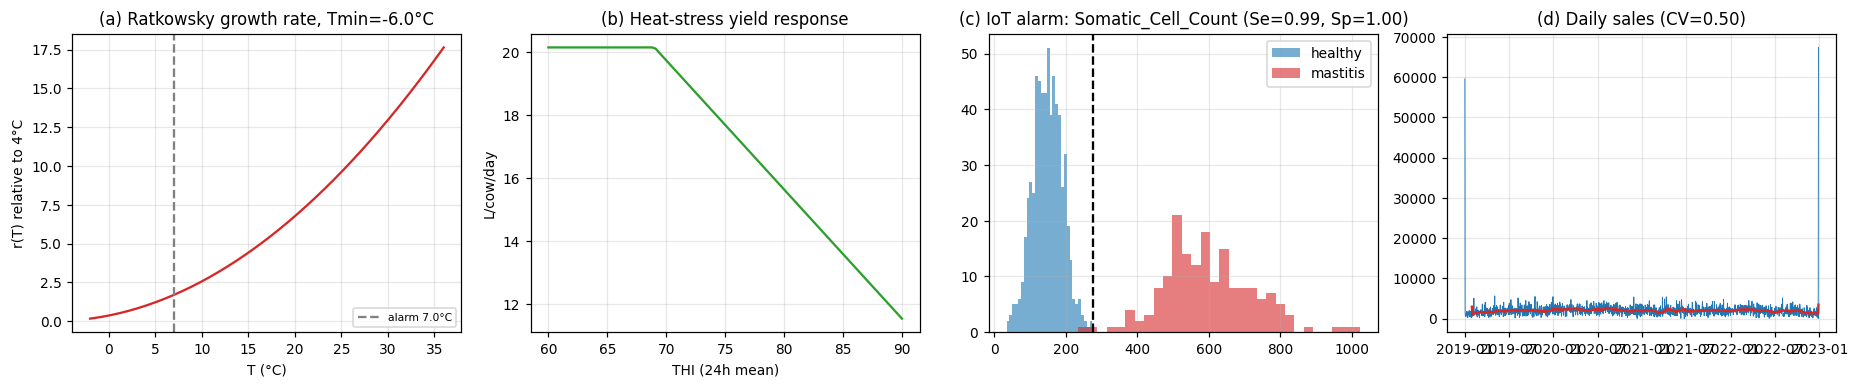

In [6]:
prov = pd.DataFrame(PROVENANCE)
prov.to_csv(f"{OUT_DIR}/calibration_provenance.csv", index=False)
print(prov.to_string(index=False, max_colwidth=70))

fig, ax = plt.subplots(1, 4, figsize=(17, 3.6))
# (a) growth model
TT = np.linspace(-2, 36, 200)
ax[0].plot(TT, [growth_rate(t) for t in TT], "C3")
if "ratkowsky" in CAL_DATA:
    g = CAL_DATA["ratkowsky"]["points"]
    ax[0].scatter(g["T"], (g["y"] / np.interp(SPOIL["Tref"], g["T"], g["y"])) ** 2, s=15, c="k", label="data (normalised)")
    ax[0].legend()
ax[0].set(title=f"(a) Ratkowsky growth rate, Tmin={SPOIL['Tmin']:.1f}°C", xlabel="T (°C)", ylabel="r(T) relative to 4°C")
ax[0].axvline(SPOIL["excursion_T"], ls="--", c="grey", label=f"alarm {SPOIL['excursion_T']}°C"); ax[0].legend(fontsize=7)
# (b) THI-yield
th = np.linspace(60, 90, 100)
ax[1].plot(th, np.maximum(FARM["yield_l"] - FARM["yield_loss_thi"] * np.maximum(th - FARM["thi_thr"], 0), 0.5 * FARM["yield_l"]), "C2")
if "thi_yield" in CAL_DATA:
    j = CAL_DATA["thi_yield"]; ax[1].scatter(j.thi, j.y, s=12, c="k")
ax[1].set(title="(b) Heat-stress yield response", xlabel="THI (24h mean)", ylabel="L/cow/day")
# (c) mastitis sensor
if "mastitis" in CAL_DATA:
    m = CAL_DATA["mastitis"]
    for lab, c in ((0, "C0"), (1, "C3")):
        ax[2].hist(m["x"][m["y"] == lab], bins=30, alpha=0.6, color=c, label=["healthy", "mastitis"][lab])
    ax[2].axvline(m["thr"], c="k", ls="--"); ax[2].legend()
    ax[2].set(title=f"(c) IoT alarm: {m['col']} (Se={FARM['sens']:.2f}, Sp={FARM['spec']:.2f})")
else:
    thx = np.linspace(60, 90, 100)
    prev = np.minimum(FARM["mast_prev"] + FARM["mast_heat_slope"] * np.maximum(thx - FARM["thi_thr"], 0), 0.5)
    div = 100 * (prev * FARM["sens"] + (1 - prev) * (1 - FARM["spec"]))
    ax[2].plot(thx, 100 * prev, "C3", label="mastitis prevalence %")
    ax[2].plot(thx, div, "C0--", label="milk diverted by alarm %")
    ax[2].legend(fontsize=7)
    ax[2].set(title=f"(c) IoT alarm model (default Se={FARM['sens']}, Sp={FARM['spec']})", xlabel="THI (24h mean)", ylabel="%")
# (d) demand
if "daily_sales" in CAL_DATA:
    ds = CAL_DATA["daily_sales"]
    ax[3].plot(ds.index, ds.values, lw=0.6); ax[3].plot(ds.rolling(30).mean(), c="C3")
    ax[3].set(title=f"(d) Daily sales (CV={DEMAND['cv']:.2f})")
else:
    ax[3].bar(["Mon","Tue","Wed","Thu","Fri","Sat","Sun"], DEMAND["dow"])
    ax[3].set(title=f"(d) Weekday factors (default), CV={DEMAND['cv']:.2f}")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig1_calibration.png", bbox_inches="tight"); plt.show()

## 3. محرك التوأم الرقمي (Hybrid DES + Continuous Physics)

```
  ┌─────────── Continuous layer (Δt = 0.5 h) ───────────┐     ┌──────── Discrete-event layer (SimPy) ────────┐
  │ ambient T/RH → THI → yield & mastitis → milking     │     │ CollectionDispatcher → RouteTrip (tanker)     │
  │ bulk-tank cooling (Newton) ⇄ cooling failures        │◄───►│   PriorityResource(fleet) · outage blocker    │
  │ Ratkowsky ageing in tanks / tankers / silo / store   │     │   Resource(reception bay) · silo back-pressure│
  │ (s,Q) production control · FEFO demand fulfilment    │     │ CoolingFailure(farm) · FeedOrder(lead time)   │
  │ feed-silo depletion                                  │     │ SmartDispatch monitor (mitigation policy)     │
  └──────────────────────────────────────────────────────┘     └───────────────────────────────────────────────┘
                    ↓ hourly state snapshot  → Recorder (time series + event log) → KPIs
```
**فرضيات النمذجة الأساسية**
- الخزان والصهريج والصومعة أوعية **متجانسة الخلط**: الحرارة والعمر المكافئ متوسطان مرجّحان بالحجم، فيُرفض الحمل كاملاً إذا فشل الاختبار (وهذا هو الواقع التشغيلي).
- **البسترة** تعيد العمر الميكروبي للصفر، ثم يتقادم المنتج المعبأ حسب حرارة مخزن التبريد، ويُصرف بأسبقية انتهاء الصلاحية (FEFO).
- التبريد يتبع **قانون نيوتن**: $T_{t+\Delta t} = T_{set} + (T_t - T_{set})e^{-\Delta t/\tau}$ ، وعند تعطل الضاغط يحل محل نقطة الضبط $T_{set}$ حرارةُ الجو.

In [7]:
PLANT = dict(
    herds=[140, 90, 160, 110, 80, 70],          # cows per farm (650 cows)
    routes=[[0, 1, 2], [3, 4, 5]],
    tank_days=1.2,                               # bulk tank capacity in days of production
    milking_windows=[(5, 7), (17, 19)],
    milk_in_temp=35.0, tank_set=4.0, tau_cool=1.0, tau_warm=10.0,
    collection_hours=[8.0, 20.0],
    n_tankers=2, tanker_cap=12_000.0, tau_tanker=40.0,
    leg_depot_farm=0.8, leg_farm_farm=0.6, leg_farm_plant=1.5, leg_plant_depot=0.5, leg_cv=0.20,
    pump_h=0.35, pump_h_per_kL=0.04, unload_h=0.4, unload_h_per_kL=0.03,
    reception_bays=1,
    silo_cap=45_000.0, silo_set=4.0, tau_silo=2.0,
    proc_rate=2_200.0, proc_window=(5, 23),
    byproduct_hour=23, byproduct_trigger=0.70, byproduct_target=0.45,
    dmi=22.0, dmi_heat=0.012, feed_cap_days=10, feed_lead_days=2.0, feed_lead_cv=0.30,
    feed_safety_days=1.5, feed_stockout_yield=0.75,
)

@dataclass
class Scenario:
    name: str
    label: str
    heat_delta: float = 0.0; heat_start: float = 20; heat_end: float = 32
    farm_fail_rate: float = 0.02; fail_temp_coef: float = 0.8; farm_fail_dur: tuple = (1.0, 3.0)
    heat_outage_p_day: float = 0.0; outage_dur: tuple = (3.0, 9.0)   # grid load-shedding during heat waves
    coldstore_breach: tuple = None           # (start_day, end_day, temp °C)
    travel_factor: float = 1.0; delay_start: float = 15; delay_end: float = 40
    breakdown_p: float = 0.01; breakdown_delay: tuple = (1.0, 3.0)
    tanker_outage: tuple = None              # (start_day, end_day, n_tankers)
    feed_lead_factor: float = 1.0
    smart_dispatch: bool = False; backup_cooling: bool = False
    extra_tankers: int = 0; rop_safety_mult: float = 1.0
    color: str = "C0"

class Vessel:
    __slots__ = ("name", "cap", "vol", "age", "temp")
    def __init__(self, name, cap, vol=0.0, age=0.0, temp=4.0):
        self.name, self.cap, self.vol, self.age, self.temp = name, cap, vol, age, temp
    def add(self, vol, age, temp):
        if vol <= 0: return
        tot = self.vol + vol
        self.age = (self.vol * self.age + vol * age) / tot
        self.temp = (self.vol * self.temp + vol * temp) / tot
        self.vol = tot
    def take(self, vol):
        v = min(vol, self.vol); age, temp = self.age, self.temp
        self.vol -= v
        if self.vol < 1e-6: self.vol, self.age = 0.0, 0.0
        return v, age, temp

class Farm:
    def __init__(self, i, herd, P):
        self.i, self.herd = i, herd
        daily = herd * FARM["yield_l"]
        self.tank = Vessel(f"F{i}", daily * P["tank_days"], vol=0.4 * daily, age=10.0, temp=P["tank_set"])
        self.failed_until = -1.0
        self.thi_ema = 65.0
        self.feed_use_day = herd * P["dmi"]
        self.feed_cap = self.feed_use_day * P["feed_cap_days"]
        self.feed = 0.6 * self.feed_cap
        self.on_order = 0.0
        self.pending = False

class KPI(dict):
    def __getattr__(self, k): return self.get(k, 0.0)
    def __setattr__(self, k, v): self[k] = v

class DairyTwin:
    def __init__(self, sc: Scenario, seed: int, P=PLANT, days=SIM_DAYS, warmup=WARMUP_DAYS, record=True):
        self.S, self.P, self.days, self.record = sc, P, days, record
        self.rng = np.random.default_rng(seed)
        self.env = simpy.Environment()
        self.warm = warmup * 24.0
        self.farms = [Farm(i, h, P) for i, h in enumerate(P["herds"])]
        n = P["n_tankers"] + sc.extra_tankers
        self.fleet = simpy.PriorityResource(self.env, capacity=n)
        self.n_fleet = n
        self.bay = simpy.Resource(self.env, capacity=P["reception_bays"])
        self.silo = Vessel("silo", P["silo_cap"], vol=0.4 * P["silo_cap"], age=12.0, temp=P["silo_set"])
        self.active_tankers = []
        # demand sizing: share of expected healthy, non-diverted supply
        supply = sum(P["herds"]) * FARM["yield_l"] * (1 - (FARM["mast_prev"] * FARM["sens"] + (1 - FARM["mast_prev"]) * (1 - FARM["spec"])))
        self.mu_d = DEMAND["share"] * supply
        sd = DEMAND["cv"] * self.mu_d
        L = DEMAND["lead_days"]
        self.ROP = (self.mu_d * L + DEMAND["service_z"] * sd * math.sqrt(L)) * sc.rop_safety_mult
        self.Q = DEMAND["q_days"] * self.mu_d
        self.fg = deque()
        init = self.ROP + 0.5 * self.Q
        for a in np.linspace(48, 0, 8): self.fg.append([init / 8, float(a)])
        self.fg_total = init
        self.producing, self.batch_left = False, 0.0
        self.noise_today = 1.0
        self.ar = 0.0
        self.cs_exc_until = -1.0
        self.k = KPI()
        self.waits = defaultdict(list)
        self.ts, self.events = [], []
        self.tanker_busy = 0.0
        self.fg_limit = (1 - SPOIL["min_remaining"]) * SPOIL["fg_shelf_days"] * 24
        for f in self.farms:
            f.feed_rop = f.feed_use_day * (P["feed_lead_days"] + P["feed_safety_days"]) * sc.rop_safety_mult
        self.Tcs = SPOIL["cs_set"]
        self.Tamb_now = FARM["amb_mean"]
        self.route_waiting = set()

    # ---------- helpers ----------
    def in_heat(self, t):  return self.S.heat_start * 24 <= t < self.S.heat_end * 24
    def in_delay(self, t): return self.S.delay_start * 24 <= t < self.S.delay_end * 24
    def rec(self): return self.env.now >= self.warm
    def log(self, kind, where, detail=""): self.events.append((self.env.now, kind, where, detail))

    def ambient(self, t):
        P, S = FARM, self.S
        h = t % 24
        self.ar = 0.97 * self.ar + self.rng.normal(0, 0.35)
        T = P["amb_mean"] + P["amb_amp"] * math.sin(2 * math.pi * (h - 9) / 24) + self.ar
        if S.heat_delta and self.in_heat(t):
            ramp = min(1.0, (t - S.heat_start * 24) / 24, (S.heat_end * 24 - t) / 24)
            T += S.heat_delta * max(ramp, 0)
        RH = float(np.clip(P["rh_mean"] - 1.5 * (T - P["amb_mean"]), 12, 98))
        THI = (1.8 * T + 32) - (0.55 - 0.0055 * RH) * (1.8 * T - 26)
        return T, RH, THI

    def leg(self, base):
        S, P = self.S, self.P
        x = base * self.rng.lognormal(-0.5 * P["leg_cv"] ** 2, P["leg_cv"])
        if self.in_delay(self.env.now): x *= S.travel_factor
        if self.rng.random() < (S.breakdown_p if self.in_delay(self.env.now) else min(S.breakdown_p, 0.01)):
            d = self.rng.uniform(*S.breakdown_delay); x += d
            self.log("breakdown", "road", f"+{d:.1f}h")
            if self.rec(): self.k.breakdowns += 1
        return x

    # ---------- discrete-event processes ----------
    def cooling_failures(self, f):
        S = self.S
        while True:
            yield self.env.timeout(1.0)
            # compressor hazard rises with condenser (ambient) temperature above 30 °C
            lam = S.farm_fail_rate * (1 + S.fail_temp_coef * max(self.Tamb_now - 30.0, 0.0)) / 24.0
            p_out = S.heat_outage_p_day * min(S.heat_delta / 9.0, 1.5) / 24.0 if (S.heat_delta and self.in_heat(self.env.now)) else 0.0
            if p_out and self.rng.random() < p_out:                    # power cut (load shedding)
                dur = self.rng.uniform(*S.outage_dur)
                if S.backup_cooling: dur = min(dur, 0.5)               # generator start-up time
                f.failed_until = max(f.failed_until, self.env.now + dur)
                self.log("power_cut", f"F{f.i}", f"{dur:.1f}h")
                if self.rec(): self.k.power_cuts += 1
            if self.rng.random() < lam:
                dur = self.rng.uniform(*S.farm_fail_dur)
                if S.backup_cooling: dur = min(dur, 1.5)
                f.failed_until = max(f.failed_until, self.env.now + dur)
                self.log("cooling_failure", f"F{f.i}", f"{dur:.1f}h")
                if self.rec(): self.k.cooling_failures += 1

    def feed_order(self, f):
        P = self.P
        qty = f.feed_cap - f.feed
        f.on_order = qty
        lt = P["feed_lead_days"] * 24 * self.rng.lognormal(-0.5 * P["feed_lead_cv"] ** 2, P["feed_lead_cv"])
        if self.in_delay(self.env.now): lt *= self.S.feed_lead_factor
        yield self.env.timeout(lt)
        f.feed = min(f.feed + qty, f.feed_cap); f.on_order = 0.0
        self.log("feed_delivery", f"F{f.i}", f"{qty/1000:.1f} t after {lt:.0f}h")

    def outage_blocker(self):
        s, e, n = self.S.tanker_outage
        yield self.env.timeout(s * 24)
        reqs = [self.fleet.request(priority=-1) for _ in range(n)]
        yield simpy.AllOf(self.env, reqs)
        self.log("tanker_outage_start", "fleet", f"{n} unit(s)")
        yield self.env.timeout(max(e * 24 - self.env.now, 0))
        for r in reqs: self.fleet.release(r)
        self.log("tanker_outage_end", "fleet")

    def dispatcher(self):
        P = self.P
        day = 0
        while True:
            for hc in P["collection_hours"]:
                t = day * 24 + hc
                if t > self.env.now: yield self.env.timeout(t - self.env.now)
                for r in P["routes"]:
                    key = tuple(r)
                    if key in self.route_waiting:          # previous call still queued → merge, don't stack
                        if self.rec(): self.k.missed_collections += 1
                        self.log("missed_collection", f"route{key}")
                        continue
                    self.env.process(self.route_trip(list(r), scheduled=True))
            day += 1

    def smart_dispatch(self):
        while True:
            yield self.env.timeout(1.0)
            for f in self.farms:
                if not f.pending and (f.tank.vol > 0.70 * f.tank.cap or f.tank.age > 0.6 * SPOIL["raw_limit_h"]):
                    self.env.process(self.route_trip([f.i], scheduled=False))
                    if self.rec(): self.k.extra_trips += 1

    def route_trip(self, farm_ids, scheduled=True):
        env, P = self.env, self.P
        for i in farm_ids: self.farms[i].pending = True
        key = tuple(farm_ids)
        if scheduled: self.route_waiting.add(key)
        t0 = env.now
        with self.fleet.request(priority=0 if scheduled else 1) as req:
            yield req
            self.route_waiting.discard(key)
            if self.rec(): self.waits["fleet" if scheduled else "fleet_extra"].append(env.now - t0)
            start = env.now
            tk = Vessel("tanker", P["tanker_cap"], temp=6.0)
            self.active_tankers.append(tk)
            yield env.timeout(self.leg(P["leg_depot_farm"]))
            for n, i in enumerate(farm_ids):
                f = self.farms[i]
                if n > 0: yield env.timeout(self.leg(P["leg_farm_farm"]))
                f.pending = False
                if f.tank.vol <= 1: continue
                if f.tank.age > SPOIL["raw_limit_h"]:                 # on-farm platform test
                    v, a, _ = f.tank.take(f.tank.vol)
                    if self.rec(): self.k.rej_farm += v
                    self.log("reject_farm", f"F{i}", f"{v:,.0f} L age={a:.0f}h")
                    continue
                vol = min(f.tank.vol, tk.cap - tk.vol)
                yield env.timeout(P["pump_h"] + P["pump_h_per_kL"] * vol / 1000)
                v, a, T = f.tank.take(vol)
                tk.add(v, a, T)
                if f.tank.vol > 1 and self.rec(): self.k.left_behind += 1
            yield env.timeout(self.leg(P["leg_farm_plant"]))
            # ---- plant reception ----
            t1 = env.now
            with self.bay.request() as bay:
                yield bay
                if self.rec(): self.waits["reception"].append(env.now - t1)
                if tk.vol > 1:
                    if self.rec(): self.waits["intake_age"].append(tk.age)
                    if tk.age > SPOIL["raw_limit_h"]:                  # load rejection
                        if self.rec(): self.k.rej_plant += tk.vol
                        self.log("reject_plant", "plant", f"{tk.vol:,.0f} L age={tk.age:.0f}h")
                        tk.vol = 0.0
                    else:
                        t2 = env.now
                        while self.silo.cap - self.silo.vol < tk.vol:   # silo back-pressure
                            yield env.timeout(0.5)
                        if self.rec(): self.waits["silo_block"].append(env.now - t2)
                        yield env.timeout(P["unload_h"] + P["unload_h_per_kL"] * tk.vol / 1000)
                        v, a, T = tk.take(tk.vol)
                        self.silo.add(v, a, T)
                        if self.rec(): self.k.intake += v
            self.active_tankers.remove(tk)
            yield env.timeout(self.leg(P["leg_plant_depot"]))
            if self.rec(): self.tanker_busy += env.now - start; self.k.trips += 1

    # ---------- continuous physics ----------
    def physics(self):
        env, P, S, k = self.env, self.P, self.S, self.k
        rate = growth_rate
        last_rec_hour = -1
        while True:
            t = env.now; h = t % 24; day = int(t // 24); rec = t >= self.warm
            if h < 1e-9:
                self.noise_today = self.rng.lognormal(-0.5 * DEMAND["cv"] ** 2, DEMAND["cv"])
            Tamb, RH, THI = self.ambient(t)
            self.Tamb_now = Tamb
            milking = any(a <= h < b for a, b in P["milking_windows"])
            milk_hours = sum(b - a for a, b in P["milking_windows"])
            grace = any(b <= h < b + 2.0 for a, b in P["milking_windows"])   # EU 853/2004: ≤8 °C within 2 h
            for f in self.farms:
                f.thi_ema += (THI - f.thi_ema) * (DT / 24.0)
                ex = max(f.thi_ema - FARM["thi_thr"], 0.0)
                # ---- milking ----
                if milking:
                    y = max(FARM["yield_l"] - FARM["yield_loss_thi"] * ex, 0.5 * FARM["yield_l"])
                    if f.feed <= 0: y *= P["feed_stockout_yield"]
                    prev = min(FARM["mast_prev"] + FARM["mast_heat_slope"] * ex, 0.5)
                    herd_eff = f.herd * (1 - prev + prev * FARM["mast_yield_ratio"])
                    vol = herd_eff * y * DT / milk_hours
                    div_share = (prev * FARM["mast_yield_ratio"] * FARM["sens"] + (1 - prev) * (1 - FARM["spec"])) / (1 - prev + prev * FARM["mast_yield_ratio"])
                    divert = vol * div_share; good = vol - divert
                    over = max(good - (f.tank.cap - f.tank.vol), 0.0); good -= over
                    f.tank.add(good, 0.0, P["milk_in_temp"])
                    if rec:
                        k.produced += vol; k.diverted += divert; k.overflow += over
                        if over > 0: self.log("overflow", f"F{f.i}", f"{over:,.0f} L")
                # ---- bulk-tank thermal + microbial ----
                if f.tank.vol > 0:
                    T0 = f.tank.temp
                    if t < f.failed_until:
                        T1 = Tamb + (T0 - Tamb) * math.exp(-DT / P["tau_warm"])
                    else:
                        tau = P["tau_cool"] * (1 + 0.05 * max(Tamb - 30, 0))
                        T1 = P["tank_set"] + (T0 - P["tank_set"]) * math.exp(-DT / tau)
                    f.tank.age += DT * rate(0.5 * (T0 + T1)); f.tank.temp = T1
                    if rec and T1 > SPOIL["farm_alarm_T"] and not milking and not grace: k.exc_farm_h += DT
                else:
                    f.tank.temp = P["tank_set"]
                # ---- feed silo ----
                use = f.herd * P["dmi"] * (1 - P["dmi_heat"] * ex) * DT / 24
                f.feed = max(f.feed - use, 0.0)
                if f.feed <= 0 and rec: k.feed_stockout_h += DT
                if f.on_order == 0 and f.feed <= f.feed_rop:
                    f.on_order = 1e-9; env.process(self.feed_order(f))
            # ---- tankers in transit (insulated) ----
            for tk in self.active_tankers:
                if tk.vol > 0:
                    T0 = tk.temp; T1 = Tamb + (T0 - Tamb) * math.exp(-DT / P["tau_tanker"])
                    tk.age += DT * rate(0.5 * (T0 + T1)); tk.temp = T1
            # ---- raw silo ----
            if self.silo.vol > 0:
                T0 = self.silo.temp; T1 = P["silo_set"] + (T0 - P["silo_set"]) * math.exp(-DT / P["tau_silo"])
                self.silo.age += DT * rate(0.5 * (T0 + T1)); self.silo.temp = T1
            # ---- cold store temperature ----
            Tcs = SPOIL["cs_set"] + self.rng.normal(0, SPOIL["cs_sd"])
            if self.rng.random() < SPOIL["cs_exc_p_day"] * DT / 24:
                self.cs_exc_until = t + self.rng.uniform(0.5, 3.0)
            if t < self.cs_exc_until: Tcs += SPOIL["cs_exc_delta"]
            if S.coldstore_breach and S.coldstore_breach[0] * 24 <= t < S.coldstore_breach[1] * 24:
                Tcs = max(Tcs, S.coldstore_breach[2] + self.rng.normal(0, 0.5))
            self.Tcs = Tcs
            if rec and Tcs > SPOIL["excursion_T"]: k.exc_store_h += DT
            r = rate(Tcs)
            for lot in self.fg: lot[1] += DT * r
            while self.fg and self.fg[0][1] >= self.fg_limit:     # FEFO write-off
                v = self.fg.popleft()[0]; self.fg_total -= v
                if rec: k.fg_expired += v
                self.log("fg_writeoff", "store", f"{v:,.0f} L")
            # ---- (s,Q) production control ----
            if not self.producing and self.fg_total <= self.ROP:
                self.producing, self.batch_left = True, self.Q
            a, b = P["proc_window"]
            if self.producing and a <= h < b:
                amt = min(P["proc_rate"] * DT, self.silo.vol, self.batch_left)
                if amt > 0:
                    self.silo.take(amt); self.fg.append([amt, 0.0]); self.fg_total += amt
                    self.batch_left -= amt
                    if rec: k.processed += amt
                elif rec:
                    k.starved_h += DT
                if self.batch_left <= 1e-6: self.producing = False
            # ---- demand (FEFO) ----
            dow = day % 7
            d = self.mu_d * DEMAND["dow"][dow] * DEMAND["hour_w"][int(h)] * 24 * (DT / 24) * self.noise_today
            served, need = 0.0, d
            while need > 1e-9 and self.fg:
                lot = self.fg[0]; s = min(lot[0], need)
                lot[0] -= s; need -= s; served += s; self.fg_total -= s
                if rec and lot[1] > 0.5 * SPOIL["fg_shelf_days"] * 24: k.low_life_sold += s
                if lot[0] <= 1e-9: self.fg.popleft()
            if rec:
                k.demand += d; k.served += served
                if need > 1e-6: k.stockout_h += DT
            # ---- by-product diversion (daily) ----
            if abs(h - P["byproduct_hour"]) < 1e-9 and self.silo.vol > P["byproduct_trigger"] * self.silo.cap:
                v, _, _ = self.silo.take(self.silo.vol - P["byproduct_target"] * self.silo.cap)
                if rec: k.byproduct += v
            # ---- recorder ----
            hr = int(t)
            if self.record and hr != last_rec_hour and abs(t - hr) < 1e-9:
                last_rec_hour = hr
                row = {"t": t, "day": t / 24, "Tamb": Tamb, "THI": THI, "Tcs": Tcs,
                       "silo": self.silo.vol, "silo_age": self.silo.age, "fg": self.fg_total,
                       "fleet_busy": self.fleet.count, "fleet_queue": len(self.fleet.queue),
                       "cum_spoil": k.rej_farm + k.rej_plant + k.fg_expired, "cum_overflow": k.overflow,
                       "cum_unmet": k.demand - k.served}
                for f in self.farms:
                    row[f"lvl{f.i}"] = f.tank.vol / f.tank.cap; row[f"T{f.i}"] = f.tank.temp
                    row[f"age{f.i}"] = f.tank.age; row[f"feed{f.i}"] = f.feed / f.feed_cap
                self.ts.append(row)
            if rec:
                k.hours += DT
                lv = [f.tank.vol / f.tank.cap for f in self.farms]
                k.tank_util_sum += np.mean(lv) * DT
                k.tank_hi_h += DT * sum(x > 0.9 for x in lv) / len(lv)
                k.silo_util_sum += self.silo.vol / self.silo.cap * DT
            yield env.timeout(DT)

    # ---------- run & KPIs ----------
    def run(self):
        env = self.env
        env.process(self.physics())
        env.process(self.dispatcher())
        for f in self.farms: env.process(self.cooling_failures(f))
        if self.S.tanker_outage: env.process(self.outage_blocker())
        if self.S.smart_dispatch: env.process(self.smart_dispatch())
        env.run(until=self.days * 24)
        return self

    def kpis(self):
        k = self.k; prod = max(k.produced, 1.0); H = max(k.hours, 1e-9)
        spoil = k.rej_farm + k.rej_plant + k.fg_expired
        w = {n: (np.mean(v) if len(v) else 0.0) for n, v in self.waits.items()}
        return {
            "Spoilage %": 100 * spoil / prod,
            "Raw rejected %": 100 * (k.rej_farm + k.rej_plant) / prod,
            "FG written-off %": 100 * k.fg_expired / prod,
            "Tank overflow %": 100 * k.overflow / prod,
            "Total loss %": 100 * (spoil + k.overflow) / prod,
            "Health diversion %": 100 * k.diverted / prod,
            "Fill rate %": 100 * k.served / max(k.demand, 1),
            "Low-life sales %": 100 * k.low_life_sold / max(k.served, 1),
            "Stockout h": k.stockout_h,
            "Fleet wait h": w.get("fleet", 0.0),
            "Reception wait h": w.get("reception", 0.0),
            "Silo block h": w.get("silo_block", 0.0),
            "Intake age eq-h": w.get("intake_age", 0.0),
            "Tank util %": 100 * k.tank_util_sum / H,
            "Tank >90% h": k.tank_hi_h,
            "Silo util %": 100 * k.silo_util_sum / H,
            "Tanker util %": 100 * self.tanker_busy / (self.n_fleet * H),
            "Farm excursion h": k.exc_farm_h,
            "Store excursion h": k.exc_store_h,
            "Feed stockout farm-h": k.feed_stockout_h,
            "Missed collections": k.missed_collections,
            "Cooling failures": k.cooling_failures,
            "Power cuts": k.power_cuts,
            "Breakdowns": k.breakdowns,
            "Trips": k.trips,
            "Milk produced kL": k.produced / 1000,
        }

    def timeseries(self): return pd.DataFrame(self.ts)
    def eventlog(self): return pd.DataFrame(self.events, columns=["t", "event", "where", "detail"])

# quick smoke test
_t0 = time.time()
_tw = DairyTwin(Scenario("smoke", "smoke"), seed=SEED, days=10, warmup=1).run()
print(f"Smoke test OK in {time.time()-_t0:.2f}s →", {k: round(v, 2) for k, v in list(_tw.kpis().items())[:8]})
print(f"Demand μ = {_tw.mu_d:,.0f} L/day | ROP = {_tw.ROP:,.0f} L | Q = {_tw.Q:,.0f} L | farm tanks = {[round(f.tank.cap) for f in _tw.farms]}")

Smoke test OK in 0.06s → {'Spoilage %': 0.0, 'Raw rejected %': 0.0, 'FG written-off %': 0.0, 'Tank overflow %': 0.0, 'Total loss %': 0.0, 'Health diversion %': 1.91, 'Fill rate %': np.float64(100.0), 'Low-life sales %': np.float64(0.0)}
Demand μ = 10,689 L/day | ROP = 19,481 L | Q = 5,752 L | farm tanks = [3385, 2176, 3868, 2660, 1934, 1692]


## 4. سيناريوهات «ماذا لو؟» (What-If Scenarios)

| السيناريو | الوصف | الاضطرابات المُدخلة |
|---|---|---|
| **S1 Baseline** | التشغيل القياسي المستقر | أعطال ضواغط نادرة (0.02/مزرعة/يوم تزداد 80% لكل درجة فوق 30°م، مدة 1–3 ساعات)، تذبذب طبيعي في زمن الرحلات (CV=20%)، أعطال طريق نادرة (1%) |
| **S2 Thermal Stress** | اضطراب التبريد والإجهاد الحراري | موجة حر +9°م (اليوم 20–32)، انقطاعات كهرباء (0.3/مزرعة/يوم، 3–9 ساعات)، إصلاح أبطأ للضواغط (6–18 ساعة)، انقطاع تبريد مخزن المنتج عند 12°م (اليوم 26–29) |
| **S3 Logistics Delays** | اضطراب النقل وتأخر الشاحنات | زمن الرحلات ×1.8 (اليوم 15–40)، أعطال طريق 12% لكل مقطع (4–14 ساعة)، خروج صهريج من الخدمة (اليوم 18–33)، تأخر توريد الأعلاف ×2.5 |
| S4 Compound *(إضافي)* | S2 + S3 معاً | أسوأ حالة واقعية: صيف مع أزمة نقل |
| S5 Mitigated *(إضافي)* | S4 + إجراءات تخفيف يقترحها التوأم | جدولة ذكية للجمع الإضافي، تبريد احتياطي بمولد في المزارع (يحد الانقطاع إلى 0.5–1.5 ساعة)، صهريج احتياطي، رفع مخزون الأمان ×1.3 |

In [8]:
S1 = Scenario("S1", "S1 Baseline", color="C0")
S2 = Scenario("S2", "S2 Thermal stress", heat_delta=9.0, heat_start=20, heat_end=32,
              farm_fail_dur=(6.0, 18.0), heat_outage_p_day=0.30, coldstore_breach=(26, 29, 12.0), color="C3")
S3 = Scenario("S3", "S3 Logistics delays", travel_factor=1.8, delay_start=15, delay_end=40,
              breakdown_p=0.12, breakdown_delay=(4.0, 14.0), tanker_outage=(18, 33, 1),
              feed_lead_factor=2.5, color="C1")
S4 = replace(S3, name="S4", label="S4 Compound (S2+S3)", heat_delta=S2.heat_delta, heat_start=S2.heat_start,
             heat_end=S2.heat_end, farm_fail_dur=S2.farm_fail_dur, heat_outage_p_day=S2.heat_outage_p_day, coldstore_breach=S2.coldstore_breach, color="C4")
S5 = replace(S4, name="S5", label="S5 Compound + mitigation", smart_dispatch=True, backup_cooling=True,
             extra_tankers=1, rop_safety_mult=1.3, color="C2")
SCENARIOS = [S1, S2, S3, S4, S5]
pd.DataFrame([asdict(s) for s in SCENARIOS]).drop(columns=["color"]).set_index("name").T

name,S1,S2,S3,S4,S5
label,S1 Baseline,S2 Thermal stress,S3 Logistics delays,S4 Compound (S2+S3),S5 Compound + mitigation
heat_delta,0.0,9.0,0.0,9.0,9.0
heat_start,20,20,20,20,20
heat_end,32,32,32,32,32
farm_fail_rate,0.02,0.02,0.02,0.02,0.02
fail_temp_coef,0.8,0.8,0.8,0.8,0.8
farm_fail_dur,"(1.0, 3.0)","(6.0, 18.0)","(1.0, 3.0)","(6.0, 18.0)","(6.0, 18.0)"
heat_outage_p_day,0.0,0.3,0.0,0.3,0.3
outage_dur,"(3.0, 9.0)","(3.0, 9.0)","(3.0, 9.0)","(3.0, 9.0)","(3.0, 9.0)"
coldstore_breach,None,"(26, 29, 12.0)",None,"(26, 29, 12.0)","(26, 29, 12.0)"


## 5. التشغيل: تكرارات Monte-Carlo بأرقام عشوائية مشتركة (CRN)
التكرار رقم *r* يستخدم البذرة `SEED + r` نفسها في كل السيناريوهات، فتكون المقارنة **مزدوجة (Paired)** ويقل التباين.

In [9]:
def run_scenarios(scenarios, reps, days=SIM_DAYS):
    rows, keep = [], {}
    for sc in scenarios:
        t0 = time.time()
        for r in range(reps):
            tw = DairyTwin(sc, seed=SEED + r, days=days, record=(r == 0)).run()
            kp = tw.kpis(); kp.update(scenario=sc.name, label=sc.label, rep=r)
            rows.append(kp)
            if r == 0: keep[sc.name] = tw
        print(f"{sc.label:28s} {reps} reps in {time.time()-t0:5.1f}s")
    return pd.DataFrame(rows), keep

RESULTS, TWINS = run_scenarios(SCENARIOS, N_REPS)
RESULTS.to_csv(f"{OUT_DIR}/kpi_replications.csv", index=False)
for name, tw in TWINS.items():
    tw.timeseries().to_csv(f"{OUT_DIR}/timeseries_{name}.csv", index=False)
    tw.eventlog().to_csv(f"{OUT_DIR}/events_{name}.csv", index=False)
print("Saved replications, time series and event logs to", OUT_DIR)

S1 Baseline                  20 reps in   6.1s
S2 Thermal stress            20 reps in   6.3s
S3 Logistics delays          20 reps in   6.1s
S4 Compound (S2+S3)          20 reps in   6.3s
S5 Compound + mitigation     20 reps in   6.6s
Saved replications, time series and event logs to /kaggle/working/dt_outputs


## 6. مسارات المحاكاة الزمنية (Simulation Trajectories)
لكل سيناريو رئيسي: (a) حرارة الجو وTHI وحرارة أسخن خزان وحرارة مخزن التبريد، (b) سجل أحداث الخطر (انقطاع كهرباء، تعطل تبريد، فيض، رفض حمولة، عطل صهريج، إعدام منتج)، (c) امتلاء خزانات المزارع، (d) مخزون الصومعة والمنتج النهائي مقابل ROP وطابور الصهاريج، (e) الخسائر التراكمية والطلب غير الملبّى. المناطق المظللة: أحمر = موجة الحر، برتقالي = نافذة اضطراب النقل، رمادي = فترة الإحماء.

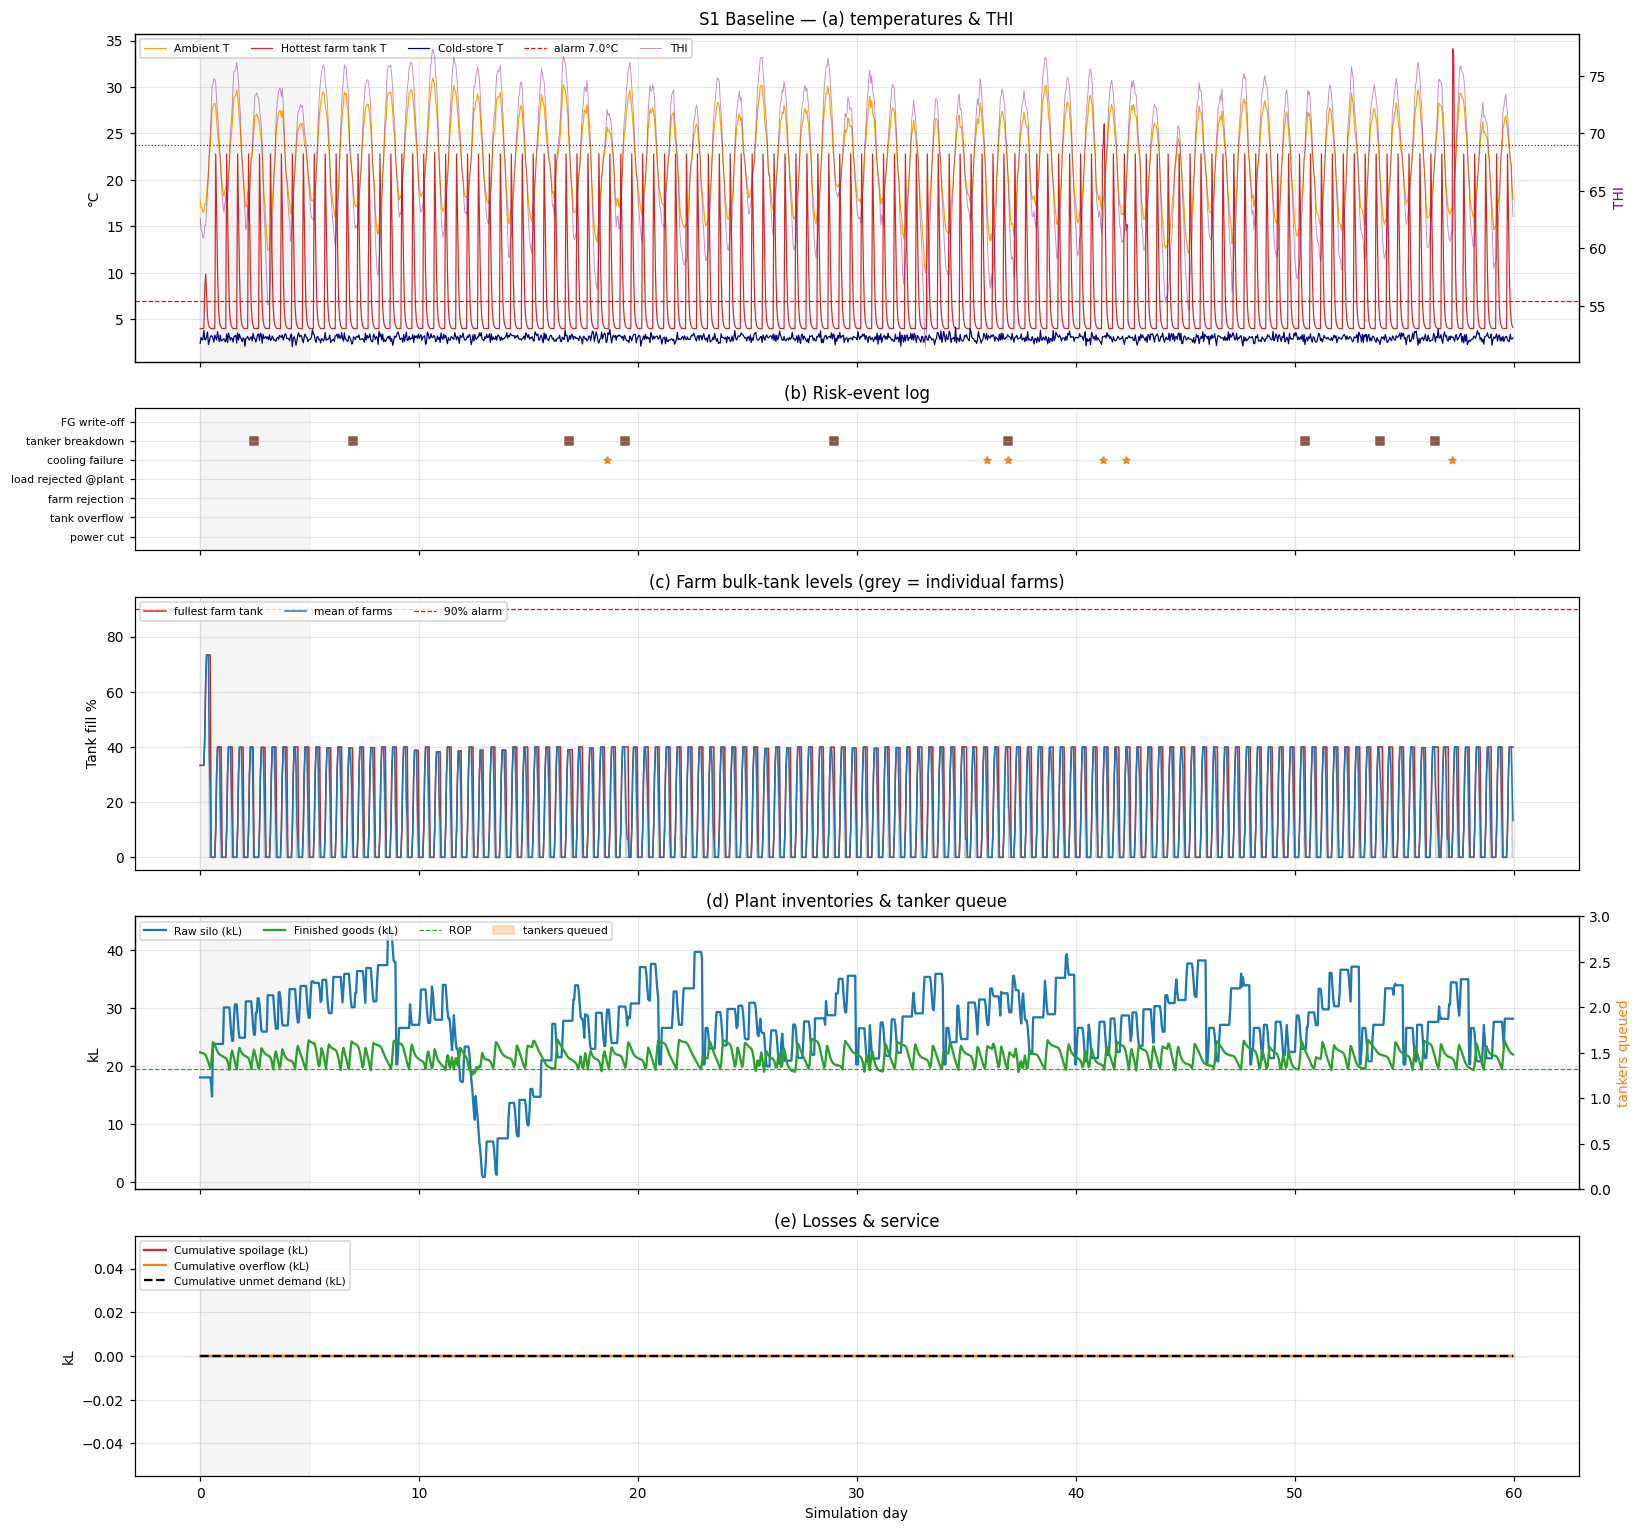

In [10]:
EVENT_STYLE = {"power_cut": ("P", "C8", "power cut"), "overflow": ("v", "C3", "tank overflow"), "reject_farm": ("X", "k", "farm rejection"),
               "reject_plant": ("X", "C4", "load rejected @plant"), "cooling_failure": ("*", "C1", "cooling failure"),
               "breakdown": ("s", "C5", "tanker breakdown"), "fg_writeoff": ("D", "C6", "FG write-off")}

def plot_trajectory(tw, fname):
    ts, ev = tw.timeseries(), tw.eventlog()
    n = len(tw.farms)
    fig, ax = plt.subplots(5, 1, figsize=(15, 14), sharex=True,
                           gridspec_kw={"height_ratios": [3, 1.3, 2.5, 2.5, 2.2]})
    # (a) temperatures
    a = ax[0]
    a.plot(ts.day, ts.Tamb, c="orange", lw=0.8, label="Ambient T")
    farmT = ts[[f"T{i}" for i in range(n)]]
    a.plot(ts.day, farmT.max(axis=1), c="C3", lw=0.8, label="Hottest farm tank T")
    a.plot(ts.day, ts.Tcs, c="navy", lw=0.8, label="Cold-store T")
    a.axhline(SPOIL["excursion_T"], c="r", ls="--", lw=0.8, label=f"alarm {SPOIL['excursion_T']}°C")
    a.set_ylabel("°C")
    a2 = a.twinx(); a2.plot(ts.day, ts.THI, c="purple", lw=0.6, alpha=0.45, label="THI")
    a2.axhline(FARM["thi_thr"], c="purple", ls=":", lw=0.8); a2.set_ylabel("THI", color="purple"); a2.grid(False)
    h1, l1 = a.get_legend_handles_labels(); h2, l2 = a2.get_legend_handles_labels()
    a.legend(h1 + h2, l1 + l2, loc="upper left", ncol=5, fontsize=7, framealpha=0.9)
    a.set_title(f"{tw.S.label} — (a) temperatures & THI")
    # (b) event raster (one row per event type)
    e_ax = ax[1]
    kinds = list(EVENT_STYLE.keys())
    for row, kind in enumerate(kinds):
        m, c, lab = EVENT_STYLE[kind]
        e = ev[ev.event == kind]
        e_ax.scatter(e.t / 24, np.full(len(e), row), marker=m, c=c, s=22)
    e_ax.set_yticks(range(len(kinds))); e_ax.set_yticklabels([EVENT_STYLE[k][2] for k in kinds], fontsize=7)
    e_ax.set_ylim(-0.7, len(kinds) - 0.3); e_ax.set_title("(b) Risk-event log")
    # (c) farm tanks
    b_ = ax[2]
    lv = 100 * ts[[f"lvl{i}" for i in range(n)]]
    for i in range(n): b_.plot(ts.day, lv[f"lvl{i}"], lw=0.5, alpha=0.25, c="grey")
    b_.plot(ts.day, lv.max(axis=1), c="C3", lw=1.0, label="fullest farm tank")
    b_.plot(ts.day, lv.mean(axis=1), c="C0", lw=1.0, label="mean of farms")
    b_.axhline(90, c="r", ls="--", lw=0.8, label="90% alarm")
    b_.set_ylabel("Tank fill %"); b_.legend(ncol=3, fontsize=7, loc="upper left"); b_.set_title("(c) Farm bulk-tank levels (grey = individual farms)")
    # (d) plant inventories
    c = ax[3]
    c.plot(ts.day, ts.silo / 1000, label="Raw silo (kL)", c="C0")
    c.plot(ts.day, ts.fg / 1000, label="Finished goods (kL)", c="C2")
    c.axhline(tw.ROP / 1000, c="C2", ls="--", lw=0.8, label="ROP")
    c.set_ylabel("kL"); c.set_title("(d) Plant inventories & tanker queue")
    c2 = c.twinx(); c2.fill_between(ts.day, ts.fleet_queue, step="post", color="C1", alpha=0.25, label="tankers queued")
    c2.set_ylabel("tankers queued", color="C1"); c2.grid(False); c2.set_ylim(0, max(3, ts.fleet_queue.max() * 1.5))
    h1, l1 = c.get_legend_handles_labels(); h2, l2 = c2.get_legend_handles_labels()
    c.legend(h1 + h2, l1 + l2, fontsize=7, loc="upper left", ncol=4)
    # (e) losses
    d = ax[4]
    d.plot(ts.day, ts.cum_spoil / 1000, c="C3", label="Cumulative spoilage (kL)")
    d.plot(ts.day, ts.cum_overflow / 1000, c="C1", label="Cumulative overflow (kL)")
    d.plot(ts.day, ts.cum_unmet / 1000, c="k", ls="--", label="Cumulative unmet demand (kL)")
    d.set_ylabel("kL"); d.set_xlabel("Simulation day"); d.legend(fontsize=7, loc="upper left"); d.set_title("(e) Losses & service")
    S = tw.S
    for axx in ax:
        axx.axvspan(0, WARMUP_DAYS, color="grey", alpha=0.08)
        if S.heat_delta: axx.axvspan(S.heat_start, S.heat_end, color="red", alpha=0.06)
        if S.travel_factor > 1 or S.breakdown_p > 0.05: axx.axvspan(S.delay_start, S.delay_end, color="orange", alpha=0.06)
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/{fname}", bbox_inches="tight"); plt.show()

plot_trajectory(TWINS["S1"], "fig2_S1_baseline.png")

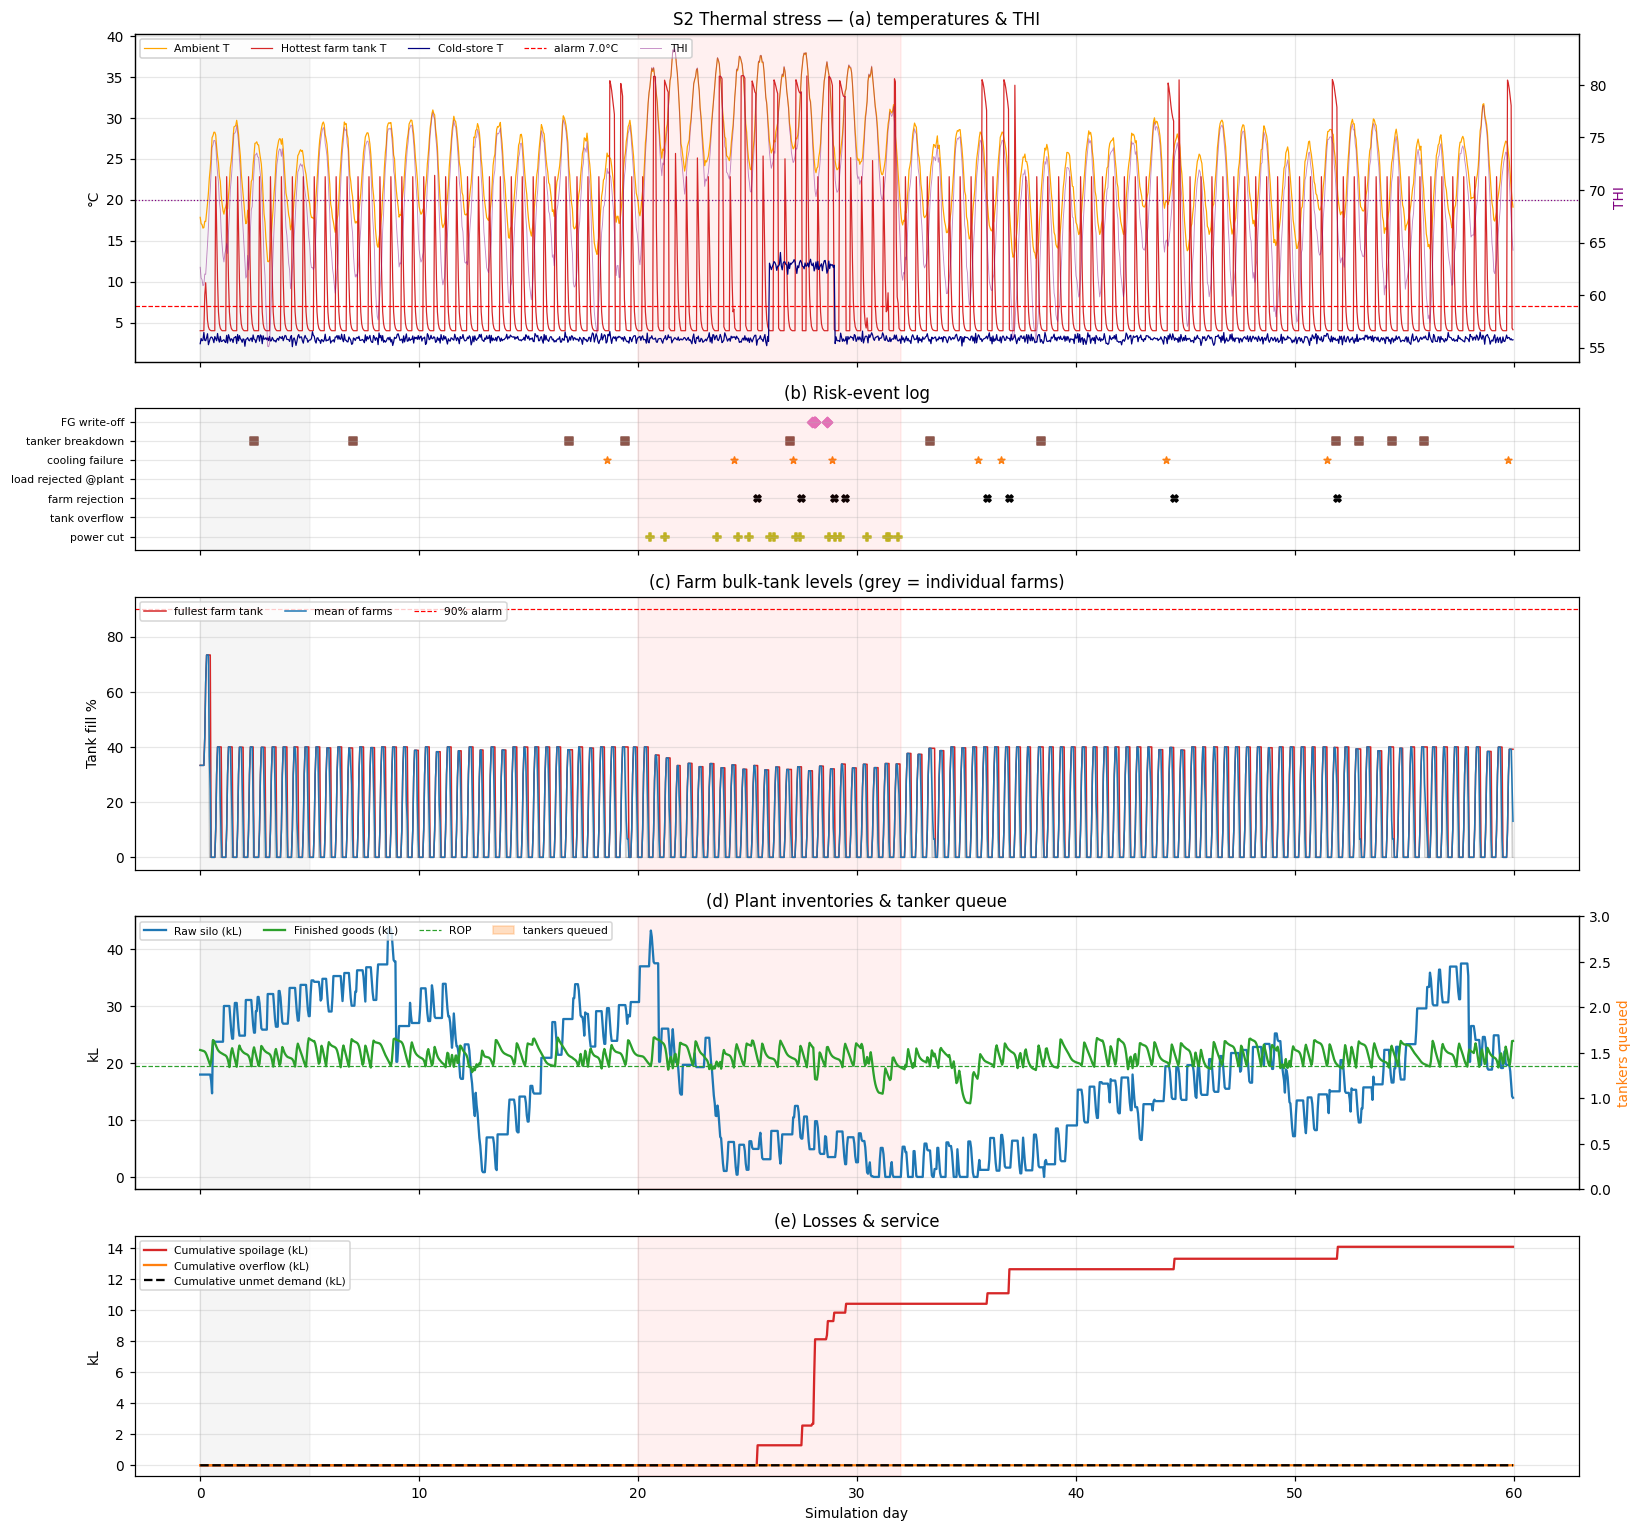

In [11]:
plot_trajectory(TWINS["S2"], "fig3_S2_thermal.png")

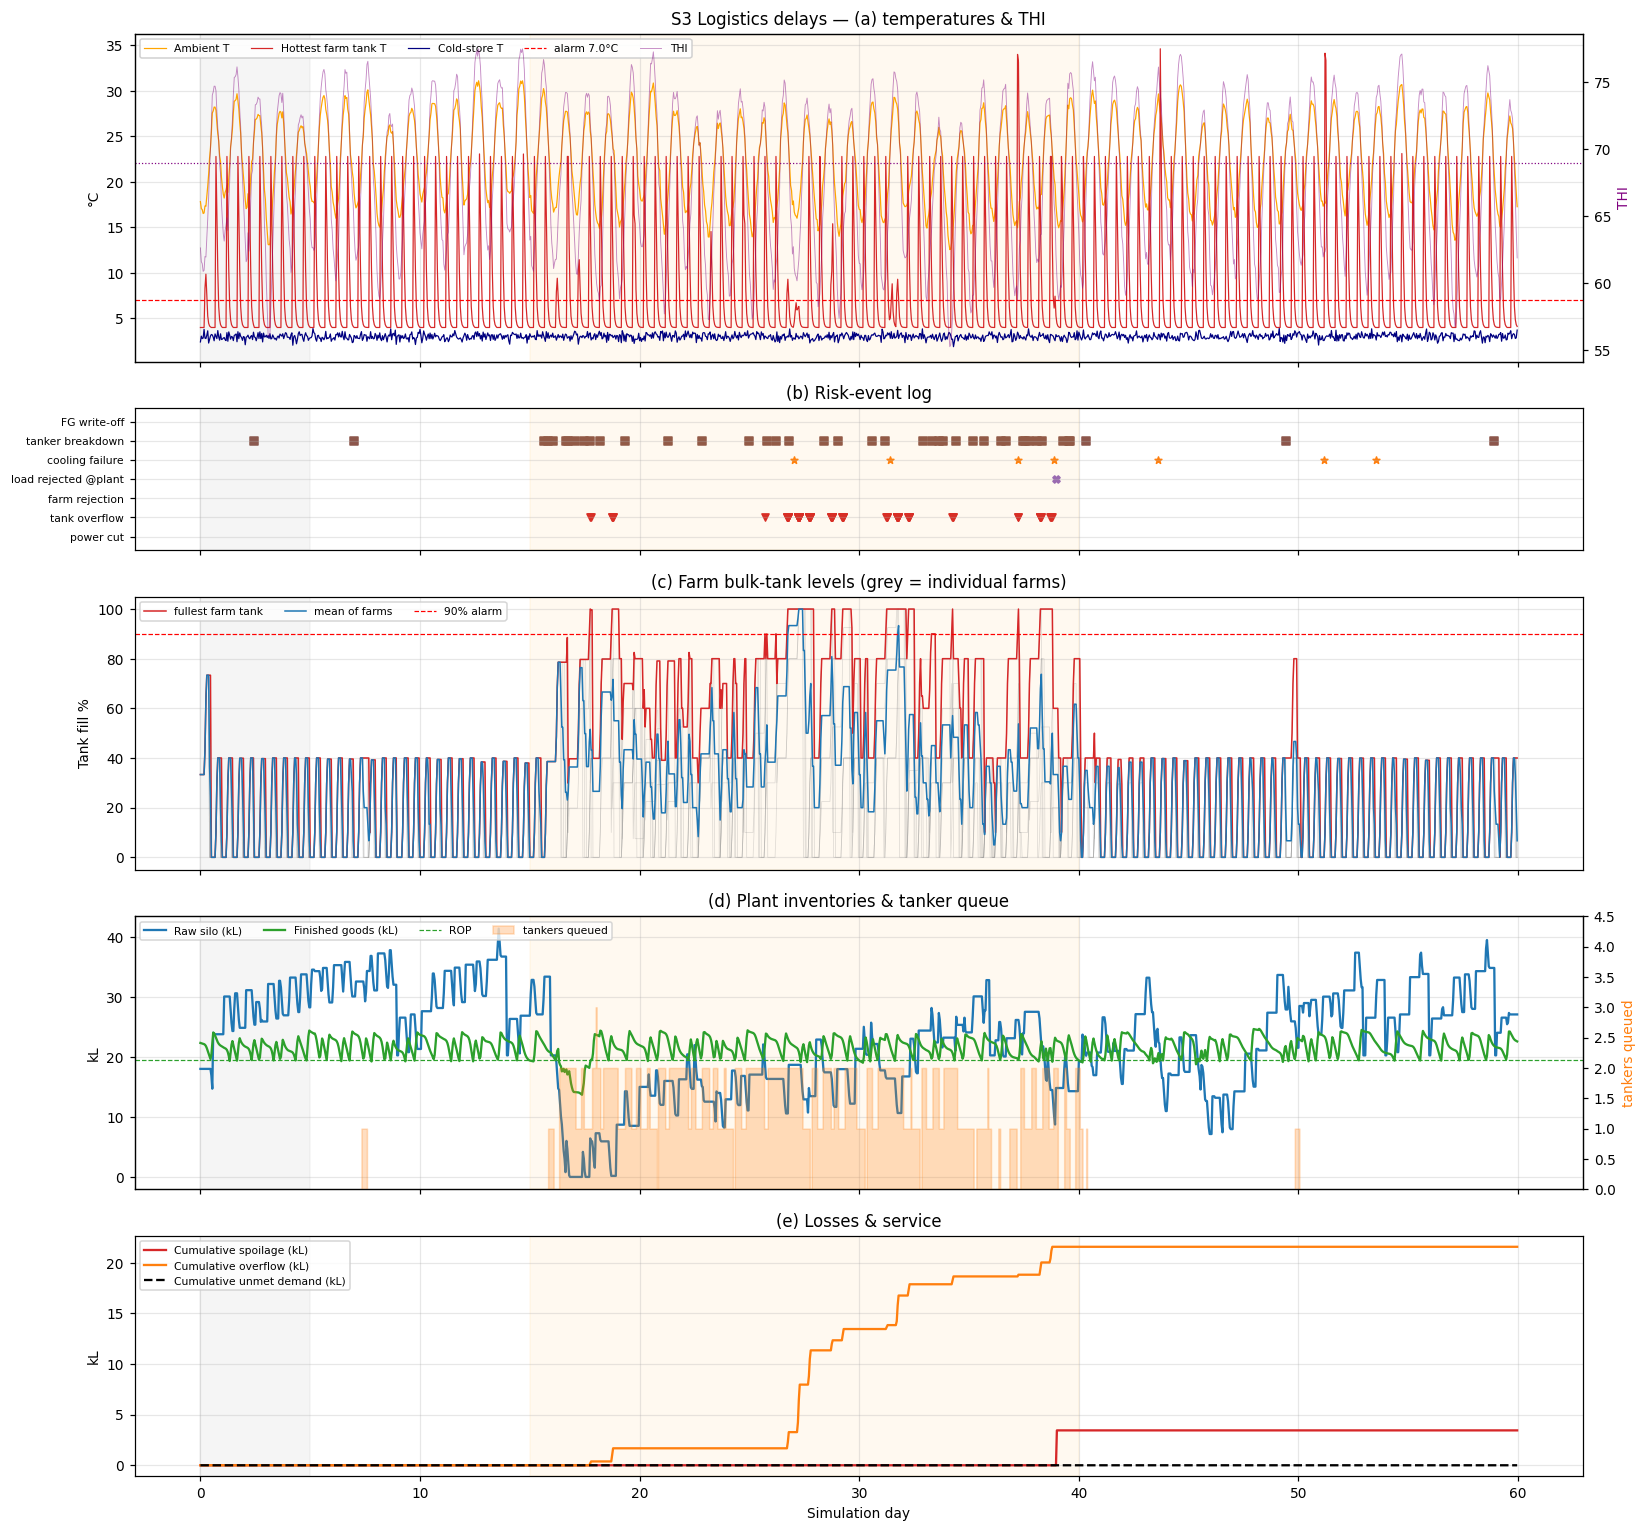

In [12]:
plot_trajectory(TWINS["S3"], "fig4_S3_logistics.png")

### 6.1 مخزون الأعلاف في الصوامع وجدول حركة الصهاريج
أثر تأخر توريد الأعلاف (S3) على مستويات الصوامع، ومخطط زمني لانتظار الصهاريج عند الاستلام.

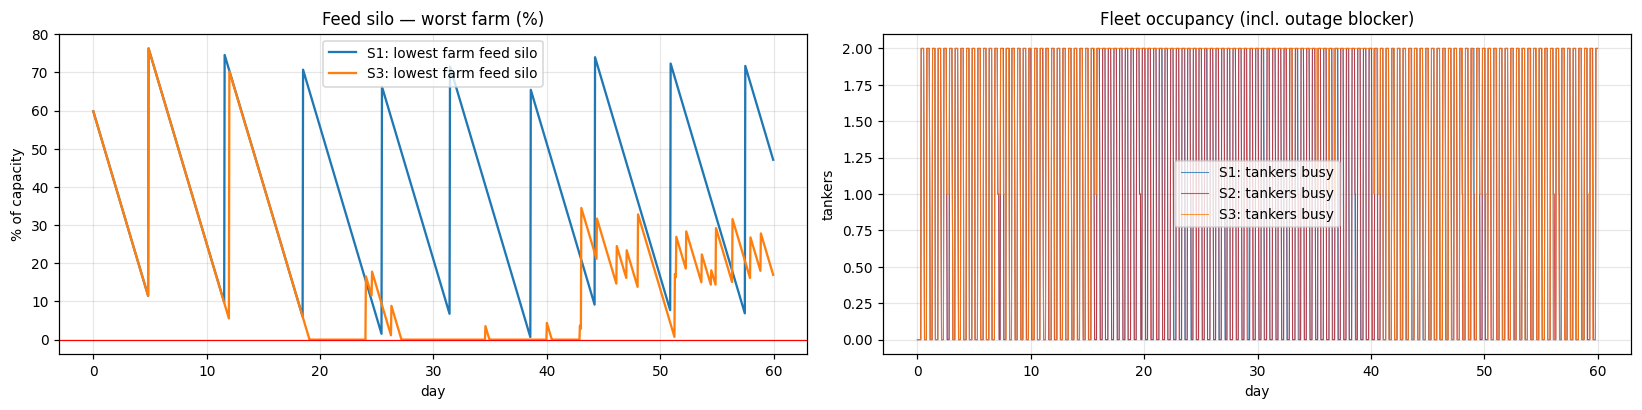

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(15, 3.8))
for name in ("S1", "S3"):
    ts = TWINS[name].timeseries()
    feed = ts[[c for c in ts.columns if c.startswith("feed")]].min(axis=1)
    ax[0].plot(ts.day, 100 * feed, label=f"{name}: lowest farm feed silo", c=TWINS[name].S.color)
ax[0].axhline(0, c="r", lw=0.8); ax[0].set(title="Feed silo — worst farm (%)", xlabel="day", ylabel="% of capacity"); ax[0].legend()
for name in ("S1", "S2", "S3"):
    ts = TWINS[name].timeseries()
    ax[1].plot(ts.day, ts.fleet_busy, label=f"{name}: tankers busy", c=TWINS[name].S.color, lw=0.7, alpha=0.8)
ax[1].set(title="Fleet occupancy (incl. outage blocker)", xlabel="day", ylabel="tankers"); ax[1].legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig5_feed_fleet.png", bbox_inches="tight"); plt.show()

## 7. جدول المقارنة الختامي (Mean ± 95% CI عبر التكرارات)

In [14]:
MAIN = ["Spoilage %", "Raw rejected %", "FG written-off %", "Tank overflow %", "Total loss %",
        "Fill rate %", "Stockout h", "Fleet wait h", "Reception wait h", "Intake age eq-h",
        "Tank util %", "Tank >90% h", "Tanker util %", "Farm excursion h", "Store excursion h",
        "Feed stockout farm-h", "Health diversion %", "Missed collections", "Low-life sales %", "Cooling failures", "Power cuts", "Breakdowns", "Trips", "Milk produced kL"]

def ci_table(df, cols=MAIN):
    g = df.groupby("label", sort=False)[cols]
    m, s, n = g.mean(), g.std(ddof=1), g.count()
    half = 1.96 * s / np.sqrt(n)
    out = m.round(2).astype(str) + " ± " + half.round(2).astype(str)
    return m, half, out

MEAN, HALF, SUMMARY = ci_table(RESULTS)
SUMMARY.T.to_csv(f"{OUT_DIR}/kpi_summary_ci95.csv")
MEAN.T.to_csv(f"{OUT_DIR}/kpi_summary_mean.csv")
SUMMARY.T

label,S1 Baseline,S2 Thermal stress,S3 Logistics delays,S4 Compound (S2+S3),S5 Compound + mitigation
Spoilage %,0.0 ± 0.0,1.33 ± 0.32,0.59 ± 0.35,4.02 ± 0.68,2.02 ± 0.46
Raw rejected %,0.0 ± 0.0,0.6 ± 0.13,0.59 ± 0.35,3.43 ± 0.57,0.64 ± 0.24
FG written-off %,0.0 ± 0.0,0.73 ± 0.26,0.0 ± 0.0,0.59 ± 0.36,1.38 ± 0.35
Tank overflow %,0.0 ± 0.0,0.0 ± 0.0,3.52 ± 0.54,1.92 ± 0.33,0.2 ± 0.09
Total loss %,0.0 ± 0.0,1.33 ± 0.32,4.11 ± 0.83,5.94 ± 0.83,2.22 ± 0.46
Fill rate %,99.82 ± 0.34,99.51 ± 0.5,98.3 ± 1.04,95.9 ± 1.3,99.49 ± 0.68
Stockout h,1.8 ± 2.93,6.25 ± 5.72,17.38 ± 11.35,44.08 ± 13.57,5.6 ± 4.52
Fleet wait h,0.0 ± 0.0,0.0 ± 0.0,4.55 ± 0.14,4.6 ± 0.14,2.43 ± 0.14
Reception wait h,0.08 ± 0.0,0.07 ± 0.0,0.05 ± 0.0,0.05 ± 0.0,0.05 ± 0.0
Intake age eq-h,18.58 ± 0.03,20.31 ± 0.18,23.41 ± 0.27,24.69 ± 0.24,23.92 ± 0.23


### 7.1 دلالة الفروق: مقارنة مزدوجة مع S1 (Paired, CRN)
بما أن كل تكرار يستخدم نفس الأرقام العشوائية، نحسب الفرق داخل كل تكرار ونختبره بـ t-test مزدوج.

In [15]:
from math import sqrt
try:
    from scipy import stats
except Exception:
    stats = None

def paired_vs_baseline(df, base="S1", cols=("Spoilage %", "Total loss %", "Fill rate %", "Fleet wait h", "Tank >90% h")):
    out = []
    b = df[df.scenario == base].set_index("rep")
    for sc in df.scenario.unique():
        if sc == base: continue
        x = df[df.scenario == sc].set_index("rep")
        for c in cols:
            d = (x[c] - b[c]).dropna()
            p = stats.ttest_1samp(d, 0).pvalue if (stats is not None and d.std() > 0) else np.nan
            out.append({"scenario": sc, "KPI": c, "Δ mean vs S1": d.mean(), "95% CI ±": 1.96 * d.std(ddof=1) / sqrt(len(d)), "p-value": p})
    return pd.DataFrame(out).round(4)

PAIRED = paired_vs_baseline(RESULTS)
PAIRED.to_csv(f"{OUT_DIR}/paired_tests_vs_S1.csv", index=False)
PAIRED.pivot(index="KPI", columns="scenario", values="Δ mean vs S1").round(2)

scenario,S2,S3,S4,S5
KPI,,,,
Fill rate %,-0.30,-1.52,-3.92,-0.32
Fleet wait h,0.00,4.55,4.60,2.43
Spoilage %,1.33,0.59,4.02,2.02
Tank >90% h,0.00,59.03,50.79,5.02
Total loss %,1.33,4.11,5.94,2.22


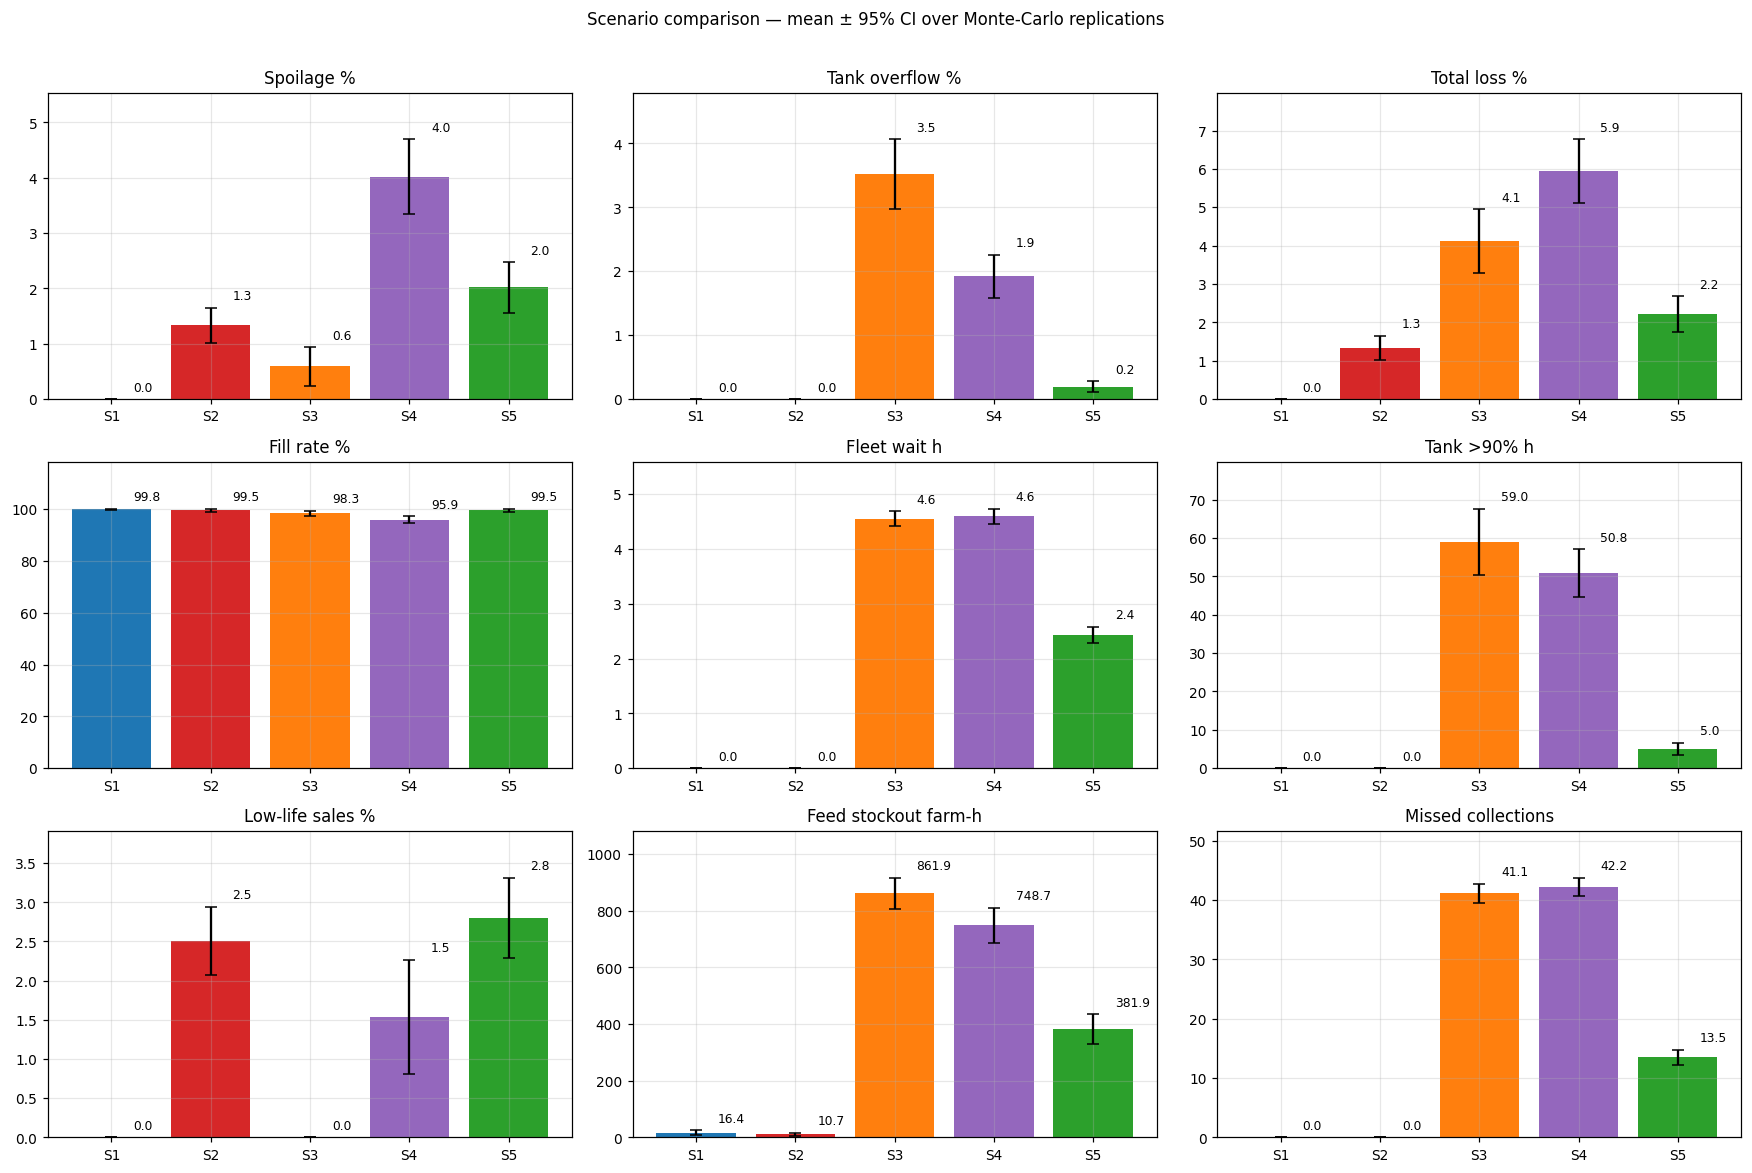

In [16]:
fig, ax = plt.subplots(3, 3, figsize=(16, 10.5))
plot_cols = ["Spoilage %", "Tank overflow %", "Total loss %", "Fill rate %", "Fleet wait h", "Tank >90% h", "Low-life sales %", "Feed stockout farm-h", "Missed collections"]
colors = [s.color for s in SCENARIOS]
for a, c in zip(ax.ravel(), plot_cols):
    a.bar(range(len(MEAN)), MEAN[c], yerr=HALF[c], color=colors, capsize=4)
    a.set_xticks(range(len(MEAN))); a.set_xticklabels([l.split(" ")[0] for l in MEAN.index])
    a.set_title(c)
    top = (MEAN[c] + HALF[c].fillna(0)).max()
    for i, (v, hw) in enumerate(zip(MEAN[c], HALF[c].fillna(0))):
        a.text(i + 0.22, v + hw + 0.02 * max(top, 1e-9), f"{v:.1f}", ha="left", va="bottom", fontsize=8)
    a.set_ylim(0, max(top * 1.18, 1e-6))
fig.suptitle("Scenario comparison — mean ± 95% CI over Monte-Carlo replications", y=1.01)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig6_kpi_comparison.png", bbox_inches="tight"); plt.show()

## 8. تحليل الحساسية (Sensitivity): أين تبدأ نقطة الانهيار؟
- **المحور اللوجستي:** معامل تأخير الرحلات من 1.0 إلى 3.0 مع ثبات باقي معاملات S3.
- **المحور الحراري:** شدة موجة الحر من 0 إلى +12°م مع ثبات باقي معاملات S2.

Sensitivity sweeps done in 34.0s


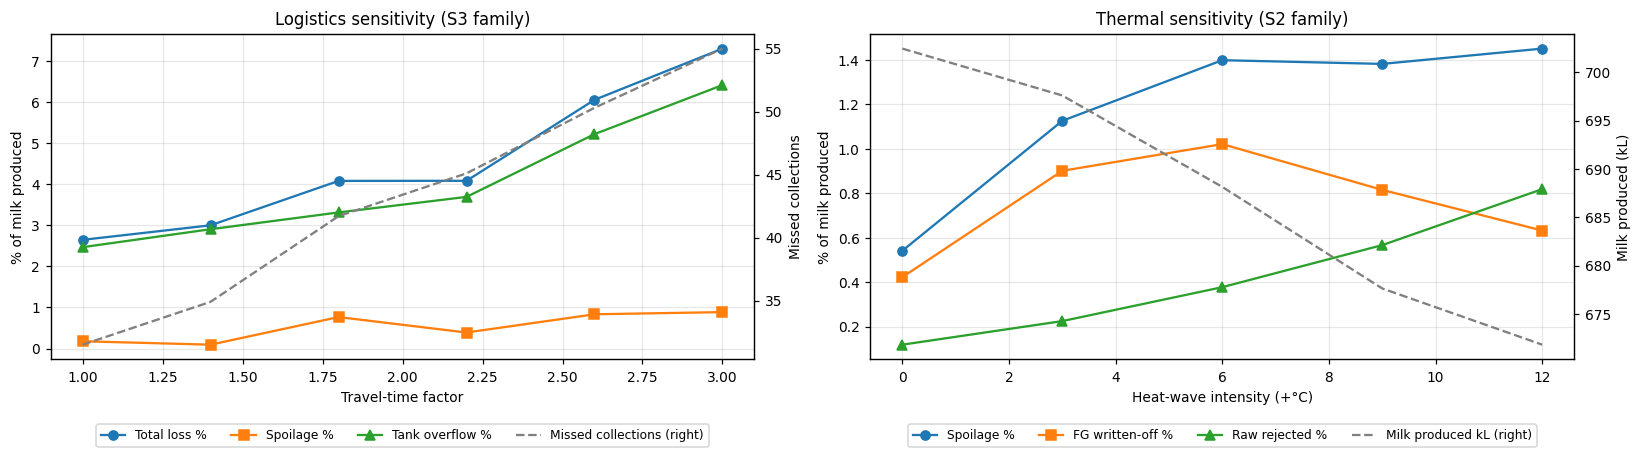

In [17]:
def sweep(base, field_name, values, reps=SWEEP_REPS):
    rows = []
    for v in values:
        sc = replace(base, name=f"{field_name}={v}", label=f"{field_name}={v}", **{field_name: v})
        for r in range(reps):
            kp = DairyTwin(sc, seed=SEED + r, record=False).run().kpis()
            kp.update(x=v); rows.append(kp)
    return pd.DataFrame(rows).groupby("x").mean(numeric_only=True)

t0 = time.time()
SW_LOG = sweep(S3, "travel_factor", [1.0, 1.4, 1.8, 2.2, 2.6, 3.0])
SW_HEAT = sweep(S2, "heat_delta", [0.0, 3.0, 6.0, 9.0, 12.0])
print(f"Sensitivity sweeps done in {time.time()-t0:.1f}s")
SW_LOG.to_csv(f"{OUT_DIR}/sensitivity_travel.csv"); SW_HEAT.to_csv(f"{OUT_DIR}/sensitivity_heat.csv")

fig, ax = plt.subplots(1, 2, figsize=(15, 4.3))
for c, st in (("Total loss %", "-o"), ("Spoilage %", "-s"), ("Tank overflow %", "-^")):
    ax[0].plot(SW_LOG.index, SW_LOG[c], st, label=c)
ax0b = ax[0].twinx(); ax0b.plot(SW_LOG.index, SW_LOG["Missed collections"], "--", c="grey", label="Missed collections (right)")
ax0b.set_ylabel("Missed collections"); ax0b.grid(False)
h1, l1 = ax[0].get_legend_handles_labels(); h2, l2 = ax0b.get_legend_handles_labels()
ax[0].legend(h1 + h2, l1 + l2, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=4, fontsize=8)
ax[0].set(title="Logistics sensitivity (S3 family)", xlabel="Travel-time factor", ylabel="% of milk produced")
for c, st in (("Spoilage %", "-o"), ("FG written-off %", "-s"), ("Raw rejected %", "-^")):
    ax[1].plot(SW_HEAT.index, SW_HEAT[c], st, label=c)
ax1b = ax[1].twinx(); ax1b.plot(SW_HEAT.index, SW_HEAT["Milk produced kL"], "--", c="grey", label="Milk produced kL (right)")
ax1b.set_ylabel("Milk produced (kL)"); ax1b.grid(False)
h1, l1 = ax[1].get_legend_handles_labels(); h2, l2 = ax1b.get_legend_handles_labels()
ax[1].legend(h1 + h2, l1 + l2, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=4, fontsize=8)
ax[1].set(title="Thermal sensitivity (S2 family)", xlabel="Heat-wave intensity (+°C)", ylabel="% of milk produced")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig7_sensitivity.png", bbox_inches="tight"); plt.show()

## 9. التحقق والصدق (Verification & Validation)
- **توازن الكتلة (Mass balance):** يجب أن تتساوى المدخلات مع المخرجات مضافاً إليها تغيّر المخزون. نتحقق من ذلك على تشغيلة كاملة لكل سيناريو.
- **صدق المعاملات:** المقارنة مع المرجع الخارجي (نسبة الهدر في بيانات Perishable إن وُجدت) ومع حدود الأدبيات.

In [18]:
def mass_balance(sc, seed=SEED):
    tw = DairyTwin(sc, seed=seed, warmup=0, record=False)
    init = sum(f.tank.vol for f in tw.farms) + tw.silo.vol + tw.fg_total
    tw.run(); k = tw.k
    end = sum(f.tank.vol for f in tw.farms) + tw.silo.vol + tw.fg_total + sum(t.vol for t in tw.active_tankers)
    inflow = k.produced
    outflow = k.diverted + k.overflow + k.rej_farm + k.rej_plant + k.fg_expired + k.byproduct + k.served
    err = init + inflow - outflow - end
    return {"scenario": sc.name, "initial kL": init / 1e3, "produced kL": inflow / 1e3, "outflows kL": outflow / 1e3,
            "final stock kL": end / 1e3, "imbalance L": err, "rel. error %": 100 * err / max(inflow, 1)}

MB = pd.DataFrame([mass_balance(s) for s in SCENARIOS]).round(4)
print(MB.to_string(index=False))
assert MB["rel. error %"].abs().max() < 0.5, "Mass balance violated!"
print("\n✔ Mass balance closes for all scenarios (in-transit milk included).")
b = SPOIL.get("benchmark_waste_pct", np.nan)
if not (isinstance(b, float) and np.isnan(b)):
    print(f"External benchmark (Perishable dataset) mean waste = {b:.2f}%  vs  twin baseline FG write-off = {MEAN.loc[S1.label,'FG written-off %']:.2f}%")
else:
    print("No external waste benchmark attached — attach the Perishable Goods dataset to enable this check.")

scenario  initial kL  produced kL  outflows kL  final stock kL  imbalance L  rel. error %
      S1     45.5954     767.1915     756.4596         56.3272          0.0           0.0
      S2     45.5954     742.1108     743.8147         43.8914          0.0           0.0
      S3     45.5954     747.8188     737.5105         55.9038         -0.0          -0.0
      S4     45.5954     725.3855     711.9099         59.0710         -0.0          -0.0
      S5     51.4397     735.7044     724.0976         63.0464         -0.0          -0.0

✔ Mass balance closes for all scenarios (in-transit milk included).
No external waste benchmark attached — attach the Perishable Goods dataset to enable this check.


## 10. الاستنتاجات الهندسية (تُولَّد آلياً من النتائج)
النص التالي يُبنى برمجياً من جداول النتائج، فيبقى متسقاً مع الأرقام حتى لو تغيّرت البيانات أو المعاملات.

In [19]:
def g(lbl, c): return MEAN.loc[lbl, c]
def ratio_txt(new, old):
    return f"×{new/old:.1f}" if old >= 0.01 else "من مستوى شبه معدوم"
L1, L2, L3, L4, L5 = (s.label for s in SCENARIOS)
lines = []
lines.append("### النتائج الرئيسية")
lines.append(f"- **التشغيل القياسي (S1):** التلف {g(L1,'Spoilage %'):.2f}% · فيض الخزانات {g(L1,'Tank overflow %'):.2f}% · تلبية الطلب {g(L1,'Fill rate %'):.1f}% · انتظار الأسطول {g(L1,'Fleet wait h'):.2f} ساعة · متوسط امتلاء خزانات المزارع {g(L1,'Tank util %'):.0f}% · عمر الحليب عند الاستلام {g(L1,'Intake age eq-h'):.1f} ساعة مكافئة عند 4°م.")
lines.append(f"- **الإجهاد الحراري (S2):** التلف {g(L2,'Spoilage %'):.2f}% ({ratio_txt(g(L2,'Spoilage %'), g(L1,'Spoilage %'))})، منه رفض حليب خام {g(L2,'Raw rejected %'):.2f}% وإعدام منتج نهائي {g(L2,'FG written-off %'):.2f}%. "
             f"انقطاعات كهرباء {g(L2,'Power cuts'):.1f} وأعطال ضواغط {g(L2,'Cooling failures'):.1f} لكل تشغيلة، وساعات مخالفة قاعدة التبريد (8°م خلال ساعتين) {g(L2,'Farm excursion h'):.0f} مقابل {g(L1,'Farm excursion h'):.0f}. "
             f"انخفض الإنتاج من {g(L1,'Milk produced kL'):.0f} إلى {g(L2,'Milk produced kL'):.0f} كيلولتر (أثر THI والالتهاب). "
             f"**خطر خفي:** {g(L2,'Low-life sales %'):.1f}% من المبيعات خرجت بأقل من نصف صلاحيتها (مقابل {g(L1,'Low-life sales %'):.1f}%)، أي أن انقطاع تبريد المخزن ينقل الخطر إلى المستهلك أكثر مما يظهر كهدر.")
lines.append(f"- **اضطراب النقل (S3):** {g(L3,'Missed collections'):.0f} جولة جمع فائتة، وانتظار الأسطول {g(L3,'Fleet wait h'):.2f} ساعة مقابل {g(L1,'Fleet wait h'):.2f}، وساعات امتلاء الخزانات فوق 90% بلغت {g(L3,'Tank >90% h'):.0f} مقابل {g(L1,'Tank >90% h'):.0f}. "
             f"الفيض {g(L3,'Tank overflow %'):.2f}%، والخسارة الكلية {g(L3,'Total loss %'):.2f}%، وتلبية الطلب {g(L3,'Fill rate %'):.2f}%، ونفاد الأعلاف {g(L3,'Feed stockout farm-h'):.0f} مزرعة·ساعة مقابل {g(L1,'Feed stockout farm-h'):.0f}.")
d2, d3, d4 = (g(L, 'Total loss %') - g(L1, 'Total loss %') for L in (L2, L3, L4))
kind = "تآزري: أكبر من مجموع الأثرين" if d4 > d2 + d3 else "أقل من مجموع الأثرين (تداخل: الحليب الذي فاض لا يمكن أن يتلف مرة ثانية)"
lines.append(f"- **المركّب (S4):** خسارة كلية {g(L4,'Total loss %'):.2f}%. مجموع أثري S2 وS3 منفردين = {d2+d3:.2f} نقطة، والأثر المشترك = {d4:.2f} نقطة ← الأثر {kind}. التلف وحده ارتفع إلى {g(L4,'Spoilage %'):.2f}% مقابل {g(L2,'Spoilage %'):.2f}% في S2 و{g(L3,'Spoilage %'):.2f}% في S3.")
red = 100 * (1 - g(L5, 'Total loss %') / max(g(L4, 'Total loss %'), 1e-6))
lines.append(f"- **التخفيف (S5):** الخسارة الكلية من {g(L4,'Total loss %'):.2f}% إلى {g(L5,'Total loss %'):.2f}% (خفض نسبي {red:.0f}%)، والجولات الفائتة من {g(L4,'Missed collections'):.0f} إلى {g(L5,'Missed collections'):.0f}، ونفاد الأعلاف من {g(L4,'Feed stockout farm-h'):.0f} إلى {g(L5,'Feed stockout farm-h'):.0f} مزرعة·ساعة، وتلبية الطلب من {g(L4,'Fill rate %'):.2f}% إلى {g(L5,'Fill rate %'):.2f}%.")
if g(L5, 'FG written-off %') > g(L4, 'FG written-off %') + 0.02:
    lines.append(f"- **مفاضلة (Trade-off):** رفع مخزون الأمان ×1.3 زاد إعدام المنتج النهائي أثناء انقطاع تبريد المخزن ({g(L4,'FG written-off %'):.2f}% ← {g(L5,'FG written-off %'):.2f}%)، لأن المخزون الأكبر أقدم وأكثر تعرضاً. الأجدى ربط مخزون الأمان بحالة سلسلة التبريد لا رفعه بشكل ثابت.")
base_loss = SW_LOG["Total loss %"].iloc[0]
bp = SW_LOG.index[SW_LOG["Total loss %"] > base_loss + 2.0]
lines.append(f"- **نقطة الانهيار اللوجستي:** تتجاوز الخسارة الكلية قيمتها عند المعامل 1.0 بنقطتين مئويتين عند معامل تأخير ≈ " + (f"{bp[0]:.1f}" if len(bp) else "أكبر من 3.0 (لم تُبلَغ)") + ".")
hb = SW_HEAT.index[SW_HEAT["Spoilage %"] >= 2 * max(SW_HEAT["Spoilage %"].iloc[0], 0.05)]
lines.append("- **نقطة الانهيار الحراري:** يتضاعف التلف مقارنة بغياب الموجة عند شدة ≈ " + (f"+{hb[0]:.0f}°م" if len(hb) else "أكبر من +12°م (لم تُبلَغ)") + " (مع أعطال التبريد وانقطاعات الكهرباء المرافقة).")
drivers = PAIRED[PAIRED.KPI == "Total loss %"].sort_values("Δ mean vs S1", ascending=False)
lines.append("- **ترتيب السيناريوهات حسب زيادة الخسارة الكلية (مقارنة مزدوجة مع S1):** " +
             " > ".join(f"{r.scenario} (+{r['Δ mean vs S1']:.2f} نقطة، p={('<0.001' if r['p-value']<0.001 else format(r['p-value'],'.3f'))})" for _, r in drivers.iterrows()))
CONCLUSIONS = "\n".join(lines)
with open(f"{OUT_DIR}/conclusions_auto.md", "w", encoding="utf-8") as fh: fh.write(CONCLUSIONS)
try:
    from IPython.display import Markdown, display
    display(Markdown(CONCLUSIONS))
except Exception:
    print(CONCLUSIONS)

### النتائج الرئيسية
- **التشغيل القياسي (S1):** التلف 0.00% · فيض الخزانات 0.00% · تلبية الطلب 99.8% · انتظار الأسطول 0.00 ساعة · متوسط امتلاء خزانات المزارع 16% · عمر الحليب عند الاستلام 18.6 ساعة مكافئة عند 4°م.
- **الإجهاد الحراري (S2):** التلف 1.33% (من مستوى شبه معدوم)، منه رفض حليب خام 0.60% وإعدام منتج نهائي 0.73%. انقطاعات كهرباء 20.9 وأعطال ضواغط 8.8 لكل تشغيلة، وساعات مخالفة قاعدة التبريد (8°م خلال ساعتين) 31 مقابل 1. انخفض الإنتاج من 703 إلى 679 كيلولتر (أثر THI والالتهاب). **خطر خفي:** 2.5% من المبيعات خرجت بأقل من نصف صلاحيتها (مقابل 0.0%)، أي أن انقطاع تبريد المخزن ينقل الخطر إلى المستهلك أكثر مما يظهر كهدر.
- **اضطراب النقل (S3):** 41 جولة جمع فائتة، وانتظار الأسطول 4.55 ساعة مقابل 0.00، وساعات امتلاء الخزانات فوق 90% بلغت 59 مقابل 0. الفيض 3.52%، والخسارة الكلية 4.11%، وتلبية الطلب 98.30%، ونفاد الأعلاف 862 مزرعة·ساعة مقابل 16.
- **المركّب (S4):** خسارة كلية 5.94%. مجموع أثري S2 وS3 منفردين = 5.44 نقطة، والأثر المشترك = 5.94 نقطة ← الأثر تآزري: أكبر من مجموع الأثرين. التلف وحده ارتفع إلى 4.02% مقابل 1.33% في S2 و0.59% في S3.
- **التخفيف (S5):** الخسارة الكلية من 5.94% إلى 2.22% (خفض نسبي 63%)، والجولات الفائتة من 42 إلى 14، ونفاد الأعلاف من 749 إلى 382 مزرعة·ساعة، وتلبية الطلب من 95.90% إلى 99.49%.
- **مفاضلة (Trade-off):** رفع مخزون الأمان ×1.3 زاد إعدام المنتج النهائي أثناء انقطاع تبريد المخزن (0.59% ← 1.38%)، لأن المخزون الأكبر أقدم وأكثر تعرضاً. الأجدى ربط مخزون الأمان بحالة سلسلة التبريد لا رفعه بشكل ثابت.
- **نقطة الانهيار اللوجستي:** تتجاوز الخسارة الكلية قيمتها عند المعامل 1.0 بنقطتين مئويتين عند معامل تأخير ≈ 2.6.
- **نقطة الانهيار الحراري:** يتضاعف التلف مقارنة بغياب الموجة عند شدة ≈ +3°م (مع أعطال التبريد وانقطاعات الكهرباء المرافقة).
- **ترتيب السيناريوهات حسب زيادة الخسارة الكلية (مقارنة مزدوجة مع S1):** S4 (+5.94 نقطة، p=<0.001) > S3 (+4.11 نقطة، p=<0.001) > S5 (+2.22 نقطة، p=<0.001) > S2 (+1.33 نقطة، p=<0.001)

### الدروس المستفادة والقرارات التشغيلية الموصى بها
1. **الحرارة تضرب عبر ثلاث قنوات:** (أ) انقطاع الكهرباء وتعطل الضواغط يرفعان حرارة الخزان كله، وبما أن الخزان متجانس فإن الرفض يشمل **الحمولة كلها** لا الجزء الدافئ فقط. (ب) THI المرتفع يخفض الإنتاج ويزيد حالات الالتهاب. (ج) يرتفع احتمال تعطل الضاغط مع حرارة المكثّف. **القرار:** إنذار IoT على حرارة الخزان عند 7°م بزمن استجابة أقل من ساعة، ومولد أو بنك جليد احتياطي في المزارع الكبيرة أولاً (وهذا ما يحاكيه `backup_cooling`).
2. **مخزن المنتج النهائي نقطة فشل منفردة، وأثرها خفي:** انقطاع تبريد لـ72 ساعة عند 12°م يستهلك أياماً من الصلاحية دفعة واحدة. لأن المخزون يدور بسرعة، لا يظهر ذلك كهدر كبير، بل كمنتج يصل المستهلك بصلاحية متبقية قصيرة (مؤشر `Low-life sales %`). **القرار:** مراقبة مستمرة لحرارة المخزن، وتسعير أو تحويل ديناميكي للدفعات المتأثرة خلال أول 6 ساعات، وإدراج «الصلاحية المتبقية عند البيع» كمؤشر أداء رسمي.
3. **الصهاريج هي «عنق الزجاجة» المرن:** فقدان صهريج واحد مع تأخير ×1.8 يجعل زمن الدورة أطول من فترة الجمع (12 ساعة)، فتتراكم الطلبات في الطابور ← امتلاء الخزانات ← فيض. **القرار:** الجدولة الذكية (`smart_dispatch`) التي ترسل رحلة إضافية عندما يتجاوز امتلاء الخزان 70% أو عمر الحليب 60% من حده، مع صهريج احتياطي أو تعاقد خارجي عند الطلب.
4. **سلسلة الأعلاف مرتبطة بالحليب:** نقطة إعادة الطلب المبنية على مهلة توريد مستقرة تنهار حين تتضاعف المهلة. **القرار:** حساب ROP ديناميكياً من المهلة المرصودة: $ROP = \bar d \cdot \hat L + z\sigma\sqrt{\hat L}$ ، ورفع مخزون الأمان مسبقاً في موسم الحر.
5. **الأثر المركّب لا يساوي مجموع الأجزاء:** الحر يقصّر عمر الحليب، والتأخير يطيل بقاءه في الخزان، فيرتفع التلف بقوة. في المقابل، الحليب الذي فاض لا يُحسب تالفاً مرة ثانية. لذلك قد يكون الأثر الكلي أكبر أو أصغر من المجموع (انظر الرقم المحسوب أعلاه). **القرار:** خطط الطوارئ يجب أن تُختبر على سيناريوهات مركّبة لا منفردة.

### حدود النموذج وتطويره
- الطلب يُطبَّع على طاقة التوأم (البيانات تمثل شبكة أوسع). للتطبيق الفعلي: اربط `mu_d` ببيانات المبيعات الفعلية للمصنع.
- شبكة التوزيع إلى نقاط البيع ممثلة بالطلب الإجمالي. يمكن إضافتها كعمليات SimPy مماثلة لـ `route_trip`.
- للتحول إلى **توأم رقمي حي**: استبدل `ambient()` وحرارة الخزانات بقراءات MQTT/IoT الفعلية بالوقت الحقيقي، وشغّل المحاكاة كأفق تنبؤي متدحرج (Rolling-horizon) كل ساعة.

### المراجع
- NRC (1971). *A guide to environmental research on animals* — صيغة THI.
- Bouraoui R. et al. (2002). *The relationship of temperature-humidity index with milk production of dairy cows in a Mediterranean climate*. Animal Research 51:479–491.
- Ratkowsky D.A. et al. (1982). *Relationship between temperature and growth rate of bacterial cultures*. J. Bacteriology 149:1–5.
- Law A.M. (2015). *Simulation Modeling and Analysis*, 5th ed. — CRN وتحليل المخرجات.
- Team SimPy — https://simpy.readthedocs.io

In [20]:
print("Files written to", OUT_DIR)
for f in sorted(os.listdir(OUT_DIR)):
    print(f"  {f:40s} {os.path.getsize(os.path.join(OUT_DIR, f))/1024:8.1f} KB")

Files written to /kaggle/working/dt_outputs
  calibration_provenance.csv                   80.1 KB
  conclusions_auto.md                           3.0 KB
  events_S1.csv                                 3.3 KB
  events_S2.csv                                 4.5 KB
  events_S3.csv                                 8.7 KB
  events_S4.csv                                 7.2 KB
  events_S5.csv                                 6.9 KB
  fig1_calibration.png                         90.7 KB
  fig2_S1_baseline.png                        528.5 KB
  fig3_S2_thermal.png                         592.8 KB
  fig4_S3_logistics.png                       670.9 KB
  fig5_feed_fleet.png                         230.2 KB
  fig6_kpi_comparison.png                     103.3 KB
  fig7_sensitivity.png                        106.8 KB
  kpi_replications.csv                         31.2 KB
  kpi_summary_ci95.csv                          2.0 KB
  kpi_summary_mean.csv                          1.9 KB
  paired_tests_vs_S1.